# Concepts, influence and model performance over time

Follow-up of the 23 October 2026 meeting. Questions:

1. **Agreement vs influence.** When a concept's factor stops agreeing with its rule, does the concept's
   influence on the mortality prediction change, across **all** concept families? Is that change due to
   *different patients* (composition) or to *the same patients changing*?
2. **Concepts vs same-year performance.** Do concept measures relate to subgroup and whole-cohort
   performance (Brier, Death-F1 at the frozen threshold) in the same year?
3. **Lead/lag.** Does a concept change at year *t* come before performance changes at *t+1, t+2, t+3*
   (and the reverse)?
4. **Year input.** What does the model's year input alone do to predictions and concept groups?
5. **The TCAV rise** seen in October: what was it?

Everything uses frozen objects only (predictors, SAEs, factor cutoffs, rules, the November CAV fits);
nothing is refitted. Context variants: **last_3** (primary) and **all_history** (auxiliary).
Outcomes are used only through **2014** (2015 deaths are incomplete).

## Glossary

| Term | Meaning |
|---|---|
| **A** (strong-activation group) | evaluation patients whose concept factor activation is above the frozen cutoff |
| **R** (rule group) | evaluation patients matching the frozen rule |
| **Agreement** | P(A given R): share of rule patients who are also in A. Also **rule F2** (how well the rule recovers A) and **overlap** (Jaccard of A and R) |
| **Four agreement groups** | R+A+ (rule and activation), R+A− (rule only), R−A+ (activation only), neither |
| **Sensitivity** of a patient | gradient of predicted death probability, projected on one CAV direction. Per group: mean **signed**, mean **absolute**, and **TCAV** (share of patients with positive value). Each is computed for each of the 50 CAV fits, then the median over fits is reported |
| **CAV estimators** | **all-negative C=0.1** (primary) and **legacy C=0.1** (alongside, used by all published November numbers) |
| **Coactivation profile shift** | 1 − cosine between a group's mean SAE activation vector in a year and in the reference year |
| **Removal effect** | change in a patient's predicted risk / Brier loss when the factor's decoder contribution is removed from the embedding |
| **Returning / composition** | between two years, *returning part* = change among patients seen in both years; *composition part* = total change − returning part (effect of patients leaving and entering). Only for measures that use no outcomes |
| **Joint patient bootstrap** | 1000 resamples of patients by id, the same resample used for every concept, year and variant; intervals are 2.5–97.5 percentiles |
| **Concept resampling** | pooled correlations and medians over concepts also draw the concepts with replacement in each replicate (a concept drawn twice counts as two concepts), so their intervals reflect which concepts are in the study as well as which patients. Tables give the point estimate, the replicate median and the interval |
| **Fixed row set** | the adjustments of one comparison (same feature, target and panel rows) all use the same rows: complete cases over the feature, the target and every control of any of them. With an outcome-based control (mortality) this means years up to 2014 |
| **SMD** | standardized mean difference of a feature between two groups: difference of means / pooled SD |
| **Death-F1** | F1 for death at the frozen threshold that maximised Death-F1 on the reference year's non-evaluation patients (never 0.5) |

Intervals are conditional on the frozen predictors, SAEs, rules and CAVs. No cutoff or pass/fail label is
applied anywhere: values, intervals and plots only.

In [1]:
import warnings

%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from concept_study import (associations, cohort, features, forecasts, measures, patient_table, paths, plots,
                           published, tables)

warnings.filterwarnings("ignore")
plots.style()
pd.set_option("display.precision", 4)
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

patient_table.build_patient_table()
measures.compute_all()
features.compute_all_features()
index = measures.load_index()
records = index["concepts"]
cav_records = [r for r in records if r["valid_fits"]]
last3_records = [r for r in cav_records if "last_3" in r["variants"]]
print("concepts without CAV fits:", {r["concept"]: r["cav_fits"] for r in records if not r["valid_fits"]})
label = {r["concept"]: f"{r['reference']} {r['build'][:2]} f{r['seed']}:{r['factor']}" for r in records}
inventory = pd.DataFrame([{"variant": v, "reference": r["reference"], "has CAV fits": bool(r["valid_fits"])}
                          for r in records for v in r["variants"]])
display(inventory.groupby(["variant", "reference"])["has CAV fits"].agg(concepts="size", with_cav_fits="sum").unstack(0))

concepts without CAV fits: {'all_history/2011/2011/42/42:267,135:32,215:260': {'all_negatives': '0 of 0 measured', 'legacy': '0 of 0 measured'}, 'all_history/2011/2011/42/42:83,135:118,215:10': {'all_negatives': '0 of 0 measured', 'legacy': '0 of 0 measured'}, 'last_3/2012/2012/42/42:254,135:190,215:74': {'all_negatives': '0 of 0 measured', 'legacy': '0 of 0 measured'}}


concepts        with_cav_fits       
variant   all_history last_3   all_history last_3
reference                                        
2007                4      4             4      4
2008                6      6             6      6
2009               10     10            10     10
2010                8      7             8      7
2011                7     14             5     14
2012               11      7            11      6
2013                7     14             7     14

## Step 1 — Support: how many patients each concept has, year by year
Every later number rests on these group sizes; empty cells stay empty (undefined, not zero).

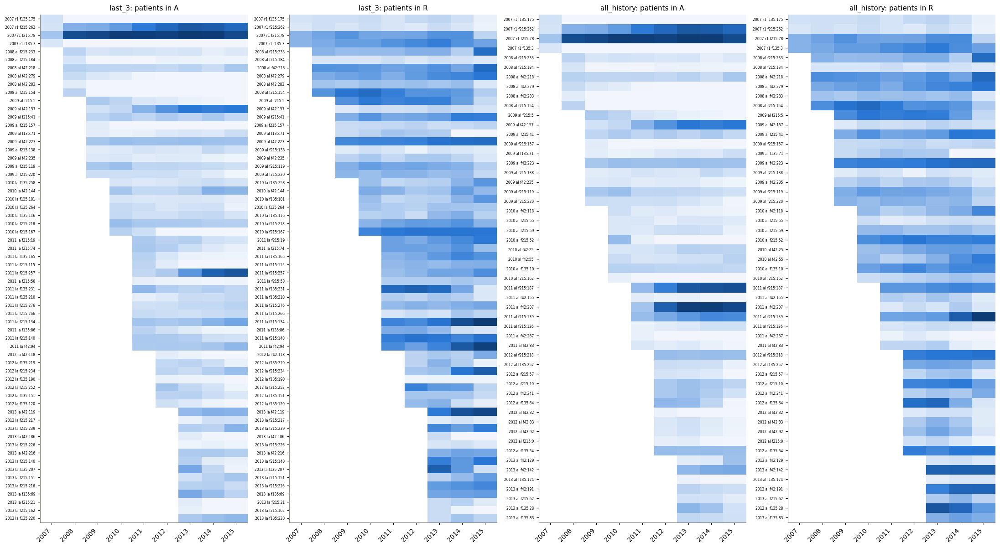

In [2]:
sizes = tables.level_table(records, {"A": "concept|n_A", "R": "concept|n_R"})
fig, axes = plt.subplots(1, 4, figsize=(20, 11))
for k, (variant, measure) in enumerate([(v, m) for v in paths.VARIANTS for m in ("A", "R")]):
    part = sizes[sizes.variants.str.contains(variant) & (sizes.measure == measure)]
    matrix = part.pivot_table(index="concept", columns="year", values="value")
    matrix = matrix.loc[sorted(matrix.index, key=lambda c: (c.split("/")[1], c))]
    plots.heatmap(axes[k], matrix.to_numpy(), [label[c] for c in matrix.index], matrix.columns,
                  title=f"{variant}: patients in {measure}", fmt="{:.0f}", colorbar=False)
    axes[k].tick_params(axis="y", labelsize=5)
fig.tight_layout()
plt.show()

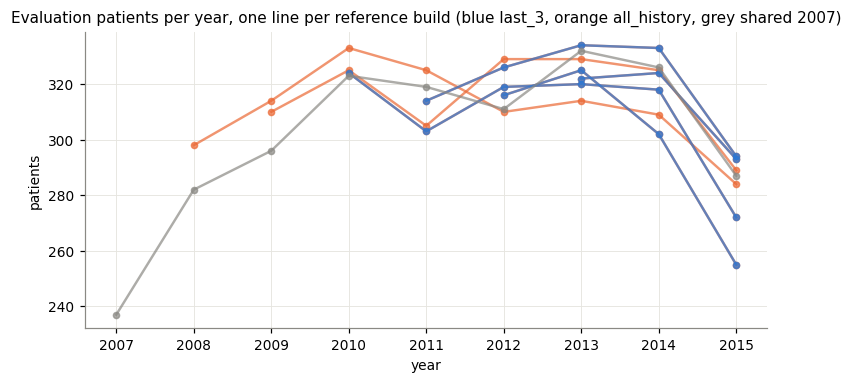

In [3]:
build_sizes = pd.concat([pd.DataFrame({"build": b["build"], "reference": b["reference"],
                                        "year": measures.load_build(b)["year"]}) for b in index["builds"]])
counts = build_sizes.groupby(["build", "reference", "year"]).size().rename("patients").reset_index()
fig, ax = plt.subplots(figsize=(8, 3.5))
for (build, reference), part in counts.groupby(["build", "reference"]):
    ax.plot(part.year, part.patients, marker="o", color=plots.VARIANT_COLOURS.get(build, plots.GREY), alpha=0.7)
ax.set(title="Evaluation patients per year, one line per reference build (blue last_3, orange all_history, grey shared 2007)",
       xlabel="year", ylabel="patients")
plt.show()

## Step 2 — Reproduce published numbers (correctness check)
Recomputed values against the November evaluation tables (legacy C=0.1) and the October whole-cohort series.

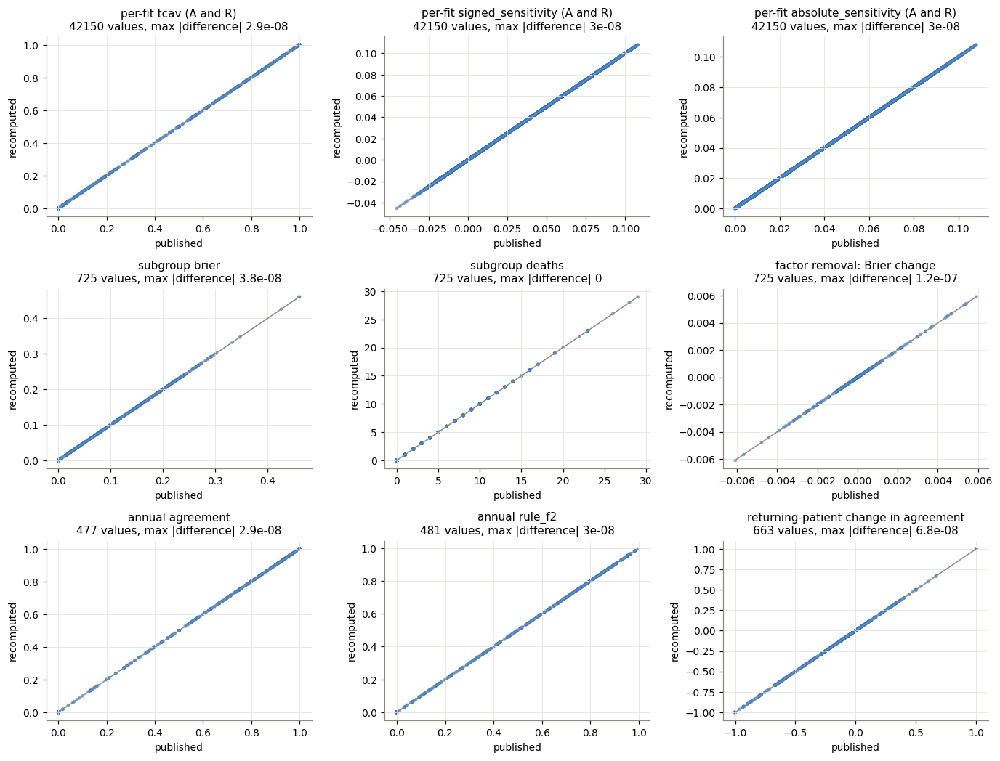

In [4]:
november = published.november_evaluation()
legacy_fits = tables.per_fit_table(cav_records, "legacy")
trajectory = november[november.source == "frozen_fit_trajectory"].rename(columns={"subgroup": "group"})
trajectory["metric"] = trajectory.metric.map({"tcav": "tcav", "signed": "signed_sensitivity", "absolute": "absolute_sensitivity"})
fit_check = trajectory.merge(legacy_fits, on=["concept", "year", "group", "draw", "metric"], suffixes=("_published", ""))

levels = tables.level_table(records, {"brier": "group|brier", "deaths": "group|deaths", "n": "group|n",
                                      "removal_brier_change": "group|removal_brier_change",
                                      "agreement": "concept|agreement", "rule_f2": "concept|rule_f2"},
                            groups=("A", "R"))
support = november[november.source == "annual_subgroup_support"].rename(columns={"subgroup": "group"})
removal = november[(november.source == "removal") & (november.metric == "removed")].rename(columns={"subgroup": "group"})
binary = november[november.source == "annual_binary"]
paired = november[november.source == "paired_binary"]
splits = tables.split_table(records, {"P_A_given_R": "concept|agreement", "A_prevalence": "concept|activation_rate",
                                      "f2": "concept|rule_f2"})

fig, axes = plots.grid(9, columns=3)
for ax, metric in zip(axes[:3], ("tcav", "signed_sensitivity", "absolute_sensitivity")):
    part = fit_check[fit_check.metric == metric]
    plots.identity(ax, part.value_published, part.value, f"per-fit {metric} (A and R)")
for ax, name in zip(axes[3:5], ("brier", "deaths")):
    merged = support.merge(levels[levels.measure == name], on=["concept", "year", "group"], suffixes=("_published", ""))
    plots.identity(ax, merged[f"{name}_published"] if f"{name}_published" in merged else merged[name], merged.value,
                   f"subgroup {name}")
merged = removal.merge(levels[levels.measure == "removal_brier_change"], on=["concept", "year", "group"],
                       suffixes=("_published", ""))
plots.identity(axes[5], merged.brier_change, merged.value, "factor removal: Brier change")
for ax, (metric, mine) in zip(axes[6:8], (("P_A_given_R", "agreement"), ("f2", "rule_f2"))):
    merged = binary[binary.metric == metric].merge(levels[(levels.measure == mine) & (levels.group == "concept")],
                                                   on=["concept", "year"], suffixes=("_published", ""))
    plots.identity(ax, merged.value_published, merged.value, f"annual {mine}")
merged = paired[paired.metric == "P_A_given_R"].merge(
    splits[splits.measure == "P_A_given_R"], left_on=["concept", "start", "year"], right_on=["concept", "start", "end"])
plots.identity(axes[8], merged.value, merged.returning, "returning-patient change in agreement")
fig.tight_layout()
plt.show()

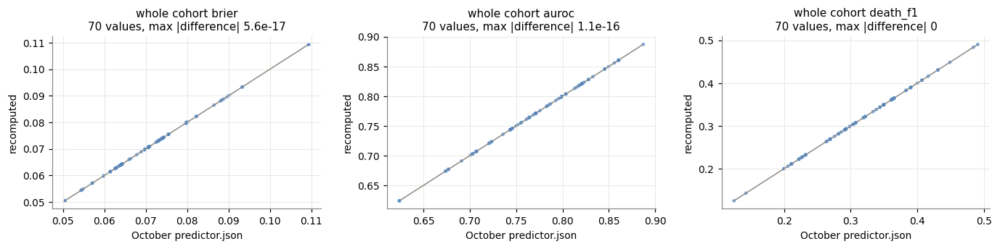

In [5]:
my_cohort = cohort.cohort_table(index)
october_cohort = pd.concat([published.october_cohort(v) for v in paths.VARIANTS])
build_of = {}
for r in records:
    for v in r["variants"]:
        build_of[(v, r["reference"])] = r["build"]
october_cohort["build"] = [build_of.get((v, ref)) for v, ref in zip(october_cohort.variant, october_cohort.reference)]
merged = october_cohort.merge(my_cohort, on=["build", "reference", "year"], suffixes=("_october", ""))
fig, axes = plots.grid(3, columns=3)
for ax, metric in zip(axes, ("brier", "auroc", "death_f1")):
    plots.identity(ax, merged[f"{metric}_october"], merged[metric], f"whole cohort {metric}", label="October predictor.json")
fig.tight_layout()
plt.show()

**Estimator check.** Held-out discrimination (AUROC of the rule contrast, median over 50 fits) of the
all-negative versus legacy C=0.1 CAVs, per concept. This is the evidence behind using all-negative as primary.

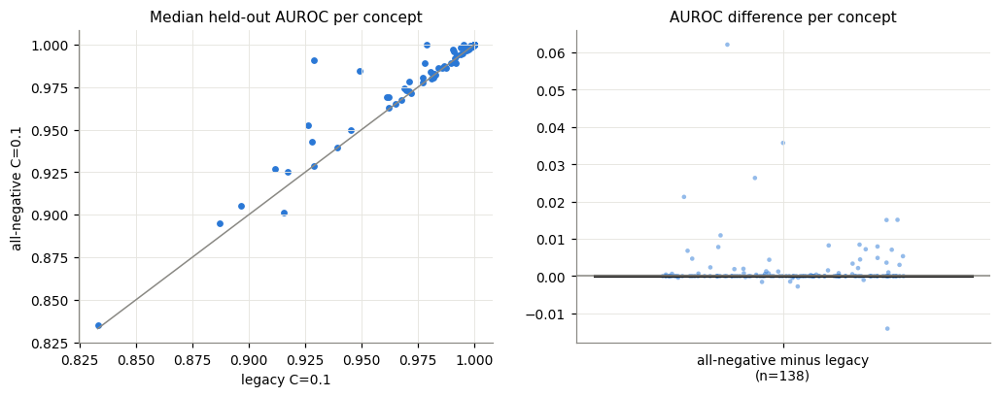

,count,mean,std,min,25%,50%,75%,max
AUROC difference,138.0,0.002,0.0072,-0.0141,0.0,0.0,0.0006,0.0621


In [6]:
auroc = published.estimator_auroc().dropna()
auroc["difference"] = auroc.all_negatives - auroc.legacy
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].scatter(auroc.legacy, auroc.all_negatives, s=12, color=plots.BLUE)
axes[0].plot([auroc.legacy.min(), 1], [auroc.legacy.min(), 1], color=plots.GREY, lw=1)
axes[0].set(xlabel="legacy C=0.1", ylabel="all-negative C=0.1", title="Median held-out AUROC per concept")
plots.strip(axes[1], {"all-negative minus legacy": auroc.difference}, title="AUROC difference per concept")
plt.show()
display(auroc.difference.describe().to_frame("AUROC difference").T)

## Step 3 — Whole-cohort performance over time
Each reference predictor scored on later years' evaluation patients (outcomes through 2014).

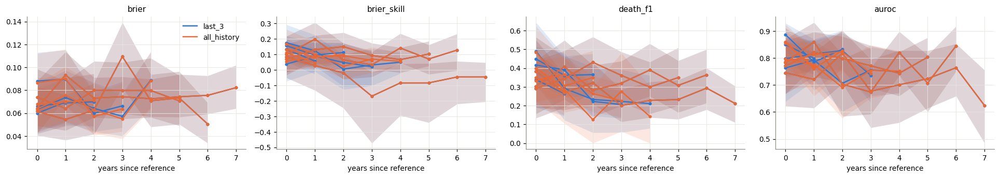

In [7]:
variants_of = {}
for r in records:
    variants_of.setdefault((r["build"], r["reference"]), set()).update(r["variants"])
rows = []
for _, row in my_cohort.iterrows():
    for v in variants_of.get((row.build, row.reference), []):
        rows.append({**row.to_dict(), "variant": v})
cohort_by_variant = pd.DataFrame(rows)
fig, axes = plots.grid(4, columns=4, width=4.4)
for ax, metric in zip(axes, ("brier", "brier_skill", "death_f1", "auroc")):
    for variant in paths.VARIANTS:
        for reference, part in cohort_by_variant[cohort_by_variant.variant == variant].groupby("reference"):
            plots.band(ax, part.years_since_reference, part[metric], part[f"{metric}_low"], part[f"{metric}_high"],
                       colour=plots.VARIANT_COLOURS[variant])
    ax.set(title=metric, xlabel="years since reference")
axes[0].legend(handles=[plt.Line2D([], [], color=c, label=v) for v, c in plots.VARIANT_COLOURS.items()])
fig.tight_layout()
plt.show()

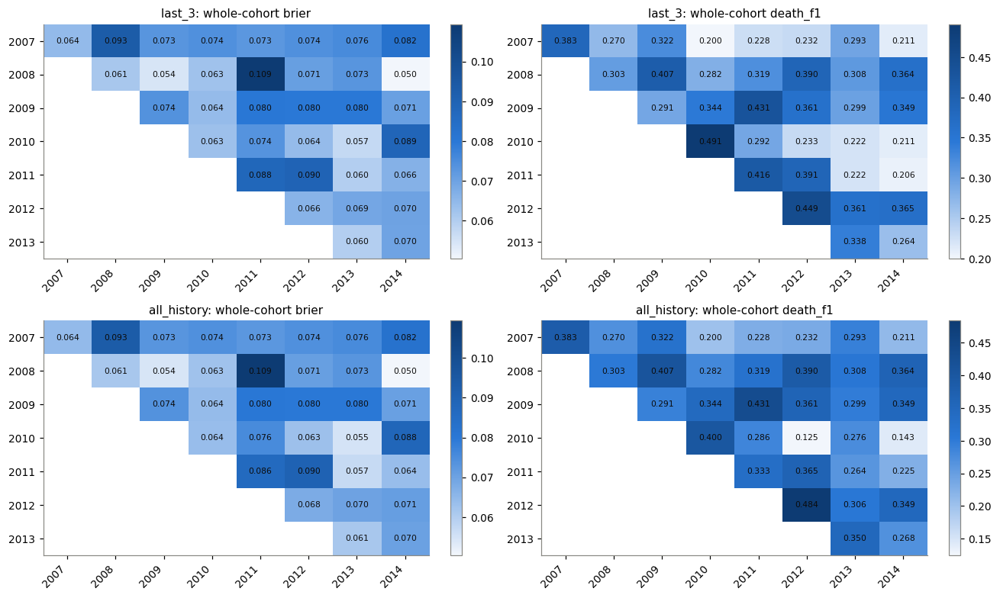

In [8]:
fig, axes = plots.grid(4, columns=2, width=6, height=3.6)
for k, (variant, metric) in enumerate([(v, m) for v in paths.VARIANTS for m in ("brier", "death_f1")]):
    matrix = cohort_by_variant[cohort_by_variant.variant == variant].pivot(index="reference", columns="year", values=metric)
    plots.heatmap(axes[k], matrix.to_numpy(), matrix.index, matrix.columns, title=f"{variant}: whole-cohort {metric}", fmt="{:.3f}")
fig.tight_layout()
plt.show()

## Step 4 — The TCAV rise, closed out
October reported families whose TCAV rose while their A group shrank or agreement fell. Below: every such
family found in the October 3-fit results, then the same families under the November 50 fits.

In [9]:
october = pd.concat([published.october_annual(v) for v in paths.VARIANTS], ignore_index=True)
october = october.dropna(subset=["tcav"])
rises = []
for (variant, family, group), part in october.groupby(["variant", "family", "group"]):
    part = part.sort_values("year")
    if len(part) < 2:
        continue
    first, last = part.iloc[0], part.iloc[-1]
    if last.tcav > first.tcav and (last.activation_rate < first.activation_rate or last.rule_f2 < first.rule_f2):
        rises.append({"variant": variant, "family": family, "group": group, "years": f"{first.year}-{last.year}",
                      "tcav first": first.tcav, "tcav last": last.tcav,
                      "activation rate first": first.activation_rate, "activation rate last": last.activation_rate,
                      "rule F2 first": first.rule_f2, "rule F2 last": last.rule_f2})
rises = pd.DataFrame(rises)
print(f"October family-groups with a TCAV rise while A shrank or rule F2 fell: {len(rises)} "
      f"of {october.groupby(['variant', 'family', 'group']).ngroups}")
display(rises)

October family-groups with a TCAV rise while A shrank or rule F2 fell: 8 of 314


,variant,family,group,years,tcav first,tcav last,activation rate first,activation rate last,rule F2 first,rule F2 last
0,all_history,"2007/42/42:268,135:171,215:262",A,2007-2015,0.0000,0.0545,0.1055,0.7247,0.2336,0.0120
1,last_3,"2007/42/42:268,135:171,215:262",A,2007-2015,0.0000,0.0545,0.1055,0.7247,0.2336,0.0120
2,last_3,"2011/42/42:49,135:91,215:140",A,2011-2015,0.0000,0.3333,0.1879,0.0884,0.9278,0.7784
3,last_3,"2013/42/42:184,135:221,215:239",A,2013-2015,0.3333,0.3409,0.1646,0.3003,0.8365,0.3799
4,last_3,"2013/42/42:184,135:221,215:239",R,2013-2015,0.3333,0.3512,0.1646,0.3003,0.8365,0.3799
5,last_3,"2013/42/42:217,135:101,215:140",A,2013-2015,0.6667,0.7778,0.1584,0.0307,0.9846,0.4737
6,last_3,"2013/42/42:217,135:101,215:140",R,2013-2015,0.6667,0.8192,0.1584,0.0307,0.9846,0.4737
7,last_3,"2014/42/42:244,135:45,215:127",A,2014-2015,0.5062,0.5667,0.0831,0.0345,0.3017,0.3125


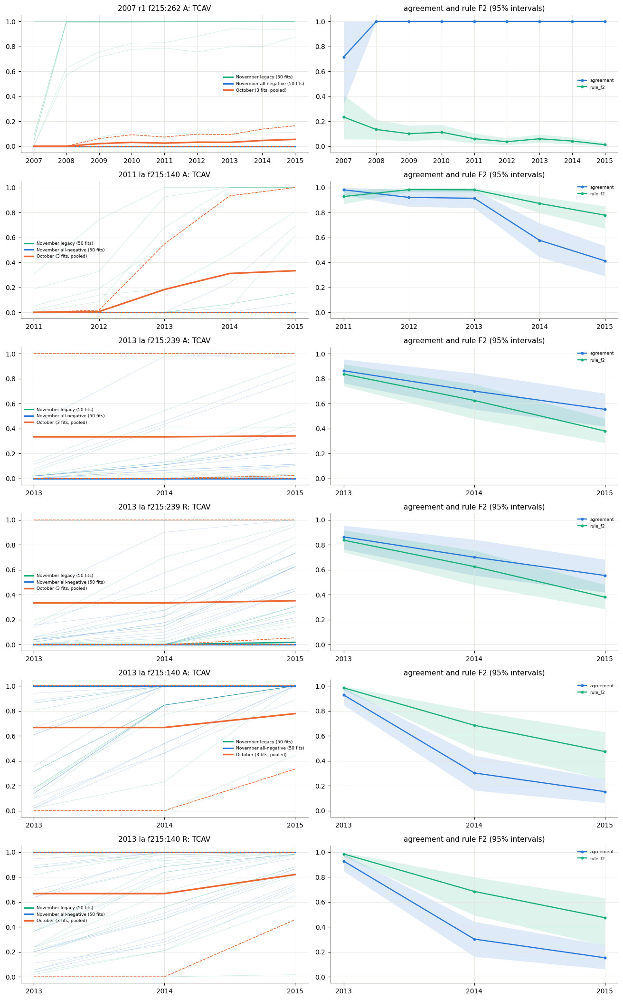

In [10]:
all_negative_fits = tables.per_fit_table(cav_records, "all_negatives")
risen = rises.drop_duplicates(["family", "group"]).head(6) if len(rises) else rises
fig, axes = plots.grid(2 * len(risen), columns=2, width=6, height=3.2)
for k, (_, rise) in enumerate(risen.iterrows()):
    record = next(r for r in cav_records if r["family"] == rise.family and rise.variant in r["variants"])
    ax = axes[2 * k]
    for fits, colour, name in ((legacy_fits, plots.AQUA, "November legacy (50 fits)"),
                               (all_negative_fits, plots.BLUE, "November all-negative (50 fits)")):
        part = fits[(fits.concept == record["concept"]) & (fits.group == rise.group) & (fits.metric == "tcav")]
        matrix = part.pivot(index="year", columns="draw", values="value")
        plots.spaghetti(ax, matrix.index, matrix.to_numpy(), colour=colour, label=name)
    old = october[(october.family == rise.family) & (october.variant == rise.variant) & (october.group == rise.group)].sort_values("year")
    for seed in ("42", "43", "44"):
        if f"tcav_{seed}" in old:
            ax.plot(old.year, old[f"tcav_{seed}"], color=plots.ORANGE, lw=1, ls="--")
    ax.plot(old.year, old.tcav, color=plots.ORANGE, lw=2.2, label="October (3 fits, pooled)")
    ax.set(title=f"{label[record['concept']]} {rise.group}: TCAV", ylim=(-0.05, 1.05))
    ax.legend(fontsize=6)
    ax = axes[2 * k + 1]
    lv = levels[(levels.concept == record["concept"]) & levels.measure.isin(["agreement", "rule_f2"])]
    for (measure, part), colour in zip(lv.groupby("measure"), (plots.BLUE, plots.AQUA)):
        plots.band(ax, part.year, part.value, part.low, part.high, colour=colour, label=measure)
    ax.set(title="agreement and rule F2 (95% intervals)", ylim=(-0.05, 1.05))
    ax.legend(fontsize=6)
for ax in axes:
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
fig.tight_layout()
plt.show()

**Why TCAV flips.** TCAV only counts the sign of each patient's sensitivity. When most patients sit close
to zero, slightly different CAV directions move many of them across zero. Per-patient signed sensitivity
(median over the 50 fits) in A, for the factor-49 family and the first two October rise families:

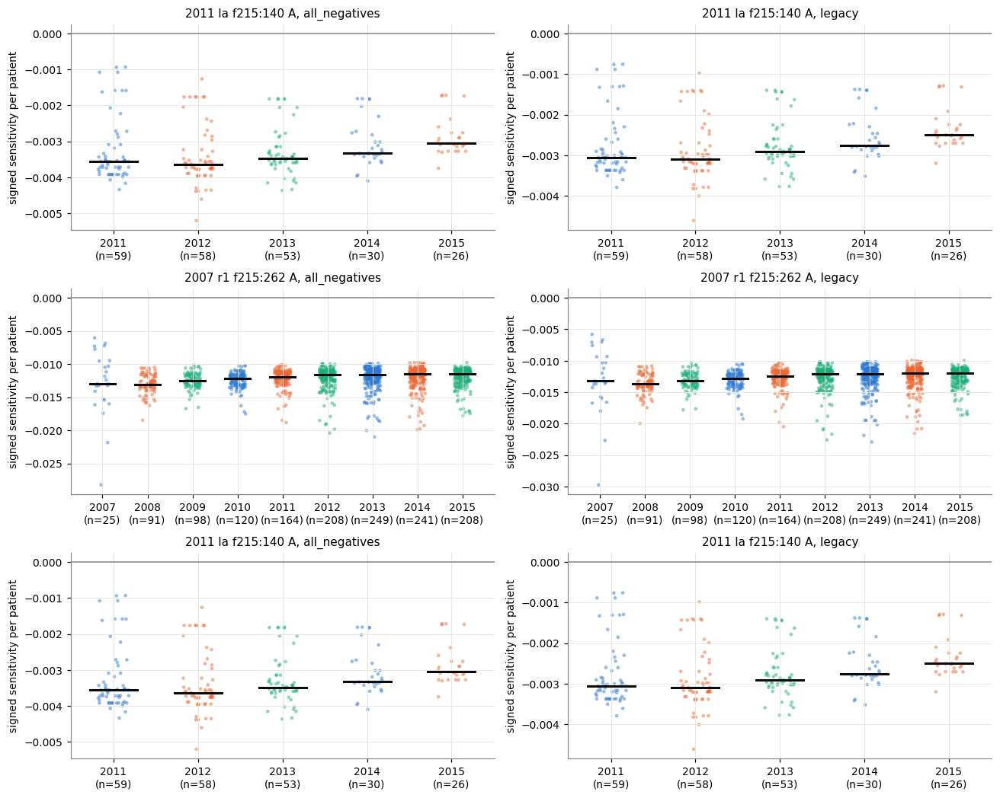

In [11]:
showcase = [next(r for r in cav_records if r["concept"].startswith("last_3/2011") and ":49," in r["concept"])]
showcase += [next(r for r in cav_records if r["family"] == f and v in r["variants"])
             for f, v in risen[["family", "variant"]].drop_duplicates().head(2).itertuples(index=False)]
fig, axes = plots.grid(2 * len(showcase), columns=2, width=6, height=3.2)
for k, record in enumerate(showcase):
    build = measures.load_build(measures.build_record(index, record))
    concept = measures.load_concept(record)
    for j, estimator in enumerate(paths.ESTIMATORS):
        values = concept[f"sensitivity_{estimator}"]
        values = values[:, np.isfinite(values).all(0)]
        groups = {}
        for year in range(record["reference"], paths.LAST_YEAR + 1):
            at = (build["year"] == year) & concept["in_A"]
            groups[str(year)] = np.median(values[at], axis=1) if at.any() else []
        plots.strip(axes[2 * k + j], groups, title=f"{label[record['concept']]} A, {estimator}",
                    ylabel="signed sensitivity per patient")
fig.tight_layout()
plt.show()

## Step 5 — Agreement versus influence, across all families
### 5a. Levels and same-interval changes

In [12]:
point, cube = associations.build_panel(cav_records)
saved = published.saved_measures(cav_records)
point = point.merge(saved, on=["concept", "group", "year"], how="left")
for name in ("fresh_rule_f2", "yearly_alignment"):
    cube[name] = point[name].to_numpy(float)[None, :]
cube["fresh_rule_gap"] = cube["fresh_rule_f2"] - cube["rule_f2"][:1]
point["fresh_rule_gap"] = cube["fresh_rule_gap"][0]
CHANGED = ["agreement", "rule_f2", "overlap", "activation_rate", "mean_activation", "profile_shift",
           "reconstruction_error", "signed_sensitivity", "absolute_sensitivity", "tcav", "share_fits_positive",
           "absolute_sensitivity_legacy", "tcav_legacy", "absolute_sensitivity_logit", "signed_sensitivity_logit",
           "removal_brier_change", "removal_risk_change",
           "brier", "death_f1", "brier_skill", "mean_risk", "feature_shift_all", "feature_shift_rule"]
associations.add_changes(point, cube, CHANGED)
variant_mask = {v: associations.in_variant(point, v) for v in paths.VARIANTS}
group_mask = {g: (point.group == g).to_numpy() for g in ("A", "R")}
outcome_mask = (point.year <= paths.LAST_OUTCOME_YEAR).to_numpy()
print(f"panel: {len(point)} concept-year-group rows, {point.concept.nunique()} concepts")

panel: 940 concept-year-group rows, 92 concepts


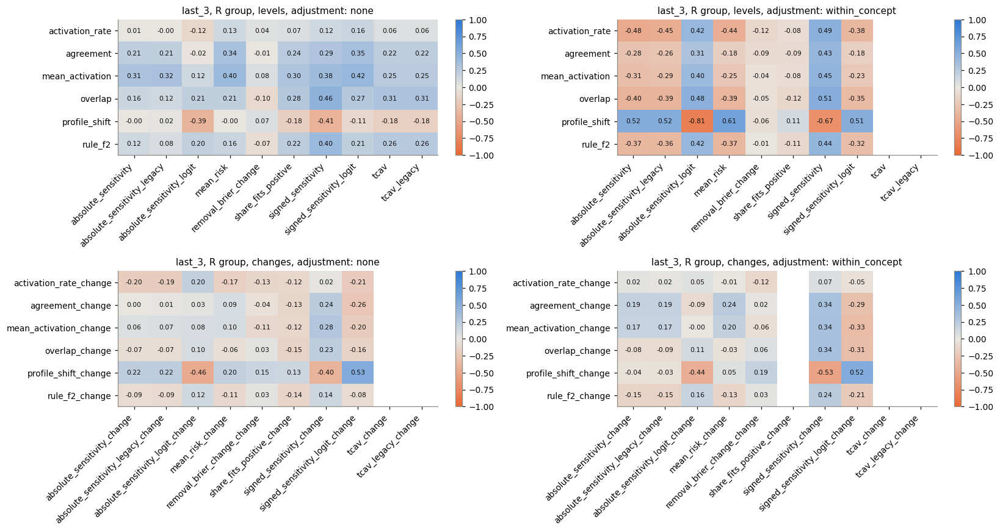

In [13]:
CONCEPT_SIDE = ["agreement", "rule_f2", "overlap", "activation_rate", "mean_activation", "profile_shift"]
INFLUENCE_SIDE = ["signed_sensitivity", "absolute_sensitivity", "tcav", "share_fits_positive",
                  "absolute_sensitivity_legacy", "tcav_legacy", "signed_sensitivity_logit", "absolute_sensitivity_logit",
                  "removal_brier_change", "mean_risk"]
LINK_ADJUSTMENTS = ("none", "within_concept", "within_concept_and_risk", "full", "full_and_risk")
cells = []
for variant in paths.VARIANTS:
    for group in ("A", "R"):
        mask = variant_mask[variant] & group_mask[group]
        for form, suffix in (("level", ""), ("change", "_change")):
            for x in CONCEPT_SIDE:
                for y in INFLUENCE_SIDE:
                    for adjustment in LINK_ADJUSTMENTS:
                        cells.append({"variant": variant, "group": group, "form": form, "feature": x + suffix,
                                      "target": y + suffix, "controls": adjustment, "mask": mask})
agreement_influence = associations.grid(point, cube, cells)
agreement_influence.to_csv(paths.OUTPUT / "agreement_vs_influence.csv", index=False)

fig, axes = plots.grid(4, columns=2, width=7.5, height=4)
for ax, (form, adjustment) in zip(axes, [(f, a) for f in ("level", "change") for a in ("none", "within_concept")]):
    part = agreement_influence[(agreement_influence.variant == "last_3") & (agreement_influence.group == "R")
                               & (agreement_influence.form == form) & (agreement_influence.adjustment == adjustment)]
    matrix = part.pivot(index="feature", columns="target", values="r")
    plots.heatmap(ax, matrix.to_numpy(), matrix.index, matrix.columns, diverging=True, limit=1,
                  title=f"last_3, R group, {form}s, adjustment: {adjustment}")
fig.tight_layout()
plt.show()

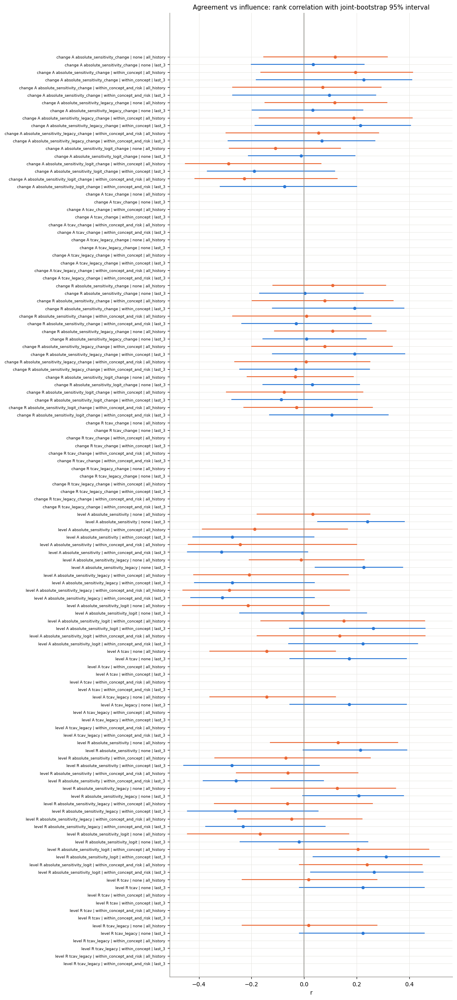

In [14]:
focus = agreement_influence[agreement_influence.feature.str.startswith("agreement")
                            & agreement_influence.target.str.contains("absolute_sensitivity|tcav")
                            & agreement_influence.adjustment.isin(["none", "within_concept", "within_concept_and_risk"])]
focus = focus.sort_values(["form", "group", "target", "adjustment", "variant"])
fig, ax = plt.subplots(figsize=(8, 0.22 * len(focus) + 1))
plots.forest(ax, [f"{r.form} {r.group} {r.target} | {r.adjustment} | {r.variant}" for r in focus.itertuples()],
             focus.r.to_numpy(), focus.low.to_numpy(), focus.high.to_numpy(),
             colours=[plots.VARIANT_COLOURS[v] for v in focus.variant],
             title="Agreement vs influence: rank correlation with joint-bootstrap 95% interval", xlabel="r")
ax.tick_params(axis="y", labelsize=6)
plt.show()

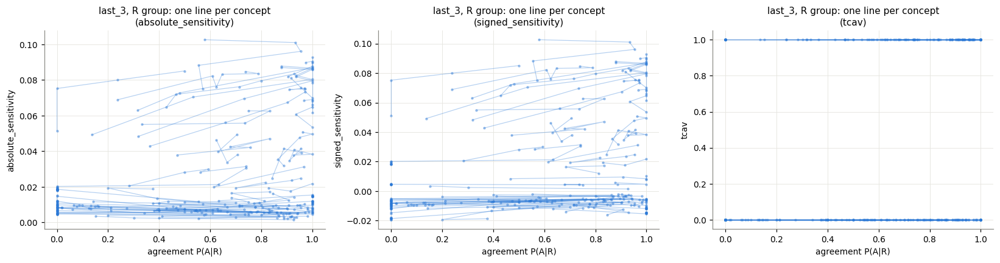

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, target in zip(axes, ("absolute_sensitivity", "signed_sensitivity", "tcav")):
    part = point[variant_mask["last_3"] & group_mask["R"]]
    for concept, rows in part.groupby("concept"):
        rows = rows.sort_values("year")
        ax.plot(rows.agreement, rows[target], color=plots.BLUE, alpha=0.35, lw=0.8, marker="o", ms=2)
    ax.set(xlabel="agreement P(A|R)", ylabel=target, title=f"last_3, R group: one line per concept\n({target})")
fig.tight_layout()
plt.show()

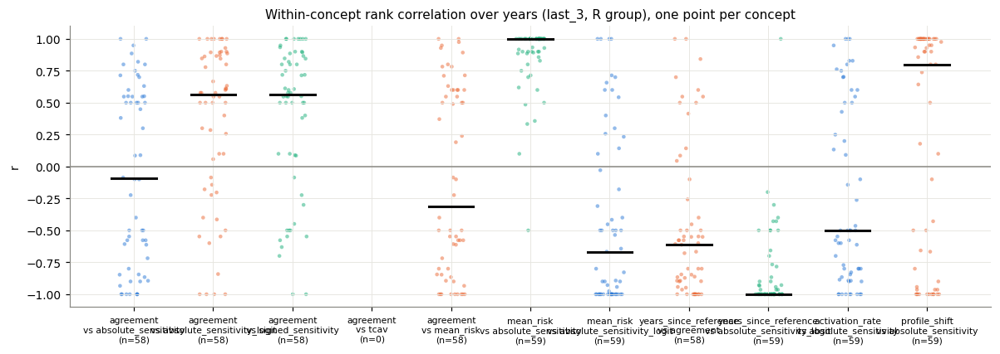

,pair,concepts with a defined r,median r,share positive
0,agreement vs absolute_sensitivity,58,-0.0929,0.4828
1,agreement vs absolute_sensitivity_logit,58,0.5625,0.7241
2,agreement vs signed_sensitivity,58,0.5641,0.7586
3,agreement vs tcav,0,NaN,NaN
4,agreement vs mean_risk,58,-0.3118,0.4483
5,mean_risk vs absolute_sensitivity,59,1.0000,0.9831
6,mean_risk vs absolute_sensitivity_logit,59,-0.6667,0.2712
7,years_since_reference vs agreement,58,-0.6098,0.2241
8,years_since_reference vs absolute_sensitivity_...,59,-1.0000,0.0169
9,activation_rate vs absolute_sensitivity,59,-0.5000,0.3559


In [16]:
within = {}
for x, y in (("agreement", "absolute_sensitivity"), ("agreement", "absolute_sensitivity_logit"),
             ("agreement", "signed_sensitivity"), ("agreement", "tcav"), ("agreement", "mean_risk"),
             ("mean_risk", "absolute_sensitivity"), ("mean_risk", "absolute_sensitivity_logit"),
             ("years_since_reference", "agreement"), ("years_since_reference", "absolute_sensitivity_logit"),
             ("activation_rate", "absolute_sensitivity"), ("profile_shift", "absolute_sensitivity")):
    sub_point, sub_cube = associations.select(point, cube, variant_mask["last_3"] & group_mask["R"])
    sub_cube["years_since_reference"] = np.broadcast_to(sub_point.years_since_reference.to_numpy(float),
                                                        sub_cube["agreement"].shape).copy()
    table = associations.within_concept(sub_point, sub_cube, x, y)
    within[f"{x}\nvs {y}"] = np.array([v[0] for v in table["values"]])
fig, ax = plt.subplots(figsize=(13, 4))
plots.strip(ax, within, title="Within-concept rank correlation over years (last_3, R group), one point per concept", ylabel="r")
ax.tick_params(axis="x", labelsize=7)
plt.show()
display(pd.DataFrame([{"pair": name.replace("\n", " "), "concepts with a defined r": int(np.isfinite(v).sum()),
                       "median r": np.nanmedian(v), "share positive": float(np.mean(v[np.isfinite(v)] > 0))}
                      for name, v in within.items()]))

**Is the link a predicted-risk effect?** The stored sensitivity is the gradient of the predicted probability
along the CAV. For a patient with predicted risk p it equals p(1-p) times the gradient of the log-odds, so it
grows with risk even when the concept's pull on the model's score does not change. Two checks: the same
correlations with the log-odds-scale sensitivity (gradient / p(1-p) per patient, same frozen fits), and with
the group's mean predicted risk added as a control (`within_concept_and_risk`, `full_and_risk`).

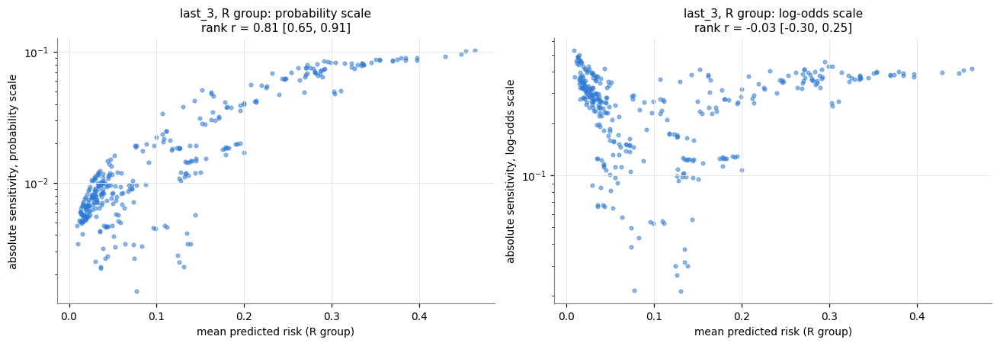

adjustment                                                                              none                                within_concept                       within_concept_and_risk  \
group form   target                                                                                                                                                                        
A     change absolute_sensitivity_change          0.03 (median 0.02) [-0.20, 0.23], 164 rows    0.23 (median 0.12) [-0.18, 0.41], 164 rows   0.10 (median -0.01) [-0.27, 0.27], 164 rows   
             absolute_sensitivity_logit_change  -0.01 (median -0.01) [-0.21, 0.19], 164 rows  -0.19 (median -0.14) [-0.37, 0.12], 164 rows  -0.07 (median -0.06) [-0.32, 0.20], 164 rows   
             mean_risk_change                     0.09 (median 0.06) [-0.15, 0.27], 164 rows    0.21 (median 0.14) [-0.16, 0.41], 164 rows         nan (median nan) [nan, nan], 164 rows   
             tcav_change                               nan (median nan) [nan, nan], 164 rows         nan (median nan) [nan, nan], 164 rows         nan (median nan) [nan, nan], 164 rows   
      level  absolute_sensitivity                  0.24 (median 0.22) [0.05, 0.38], 227 rows  -0.27 (median -0.22) [-0.42, 0.04], 227 rows  -0.31 (median -0.23) [-0.44, 0.01], 227 rows   
             absolute_sensitivity_logit         -0.01 (median -0.01) [-0.24, 0.24], 227 rows    0.26 (median 0.25) [-0.06, 0.46], 227 rows    0.22 (median 0.21) [-0.06, 0.43], 227 rows   
             mean_risk                             0.30 (median 0.28) [0.11, 0.44], 227 rows  -0.14 (median -0.12) [-0.34, 0.14], 227 rows         nan (median nan) [nan, nan], 227 rows   
             tcav                                 0.17 (median 0.17) [-0.05, 0.39], 227 rows         nan (median nan) [nan, nan], 227 rows         nan (median nan) [nan, nan], 227 rows   
R     change absolute_sensitivity_change          0.00 (median 0.03) [-0.17, 0.23], 208 rows    0.19 (median 0.14) [-0.12, 0.38], 208 rows   -0.03 (median 0.01) [-0.24, 0.26], 208 rows   
             absolute_sensitivity_logit_change    0.03 (median 0.04) [-0.16, 0.21], 208 rows  -0.09 (median -0.03) [-0.28, 0.20], 208 rows    0.11 (median 0.10) [-0.13, 0.32], 208 rows   
             mean_risk_change                     0.09 (median 0.07) [-0.14, 0.27], 208 rows    0.24 (median 0.15) [-0.10, 0.39], 208 rows         nan (median nan) [nan, nan], 208 rows   
             tcav_change                               nan (median nan) [nan, nan], 208 rows         nan (median nan) [nan, nan], 208 rows         nan (median nan) [nan, nan], 208 rows   
      level  absolute_sensitivity                 0.21 (median 0.20) [-0.00, 0.39], 269 rows  -0.28 (median -0.23) [-0.46, 0.06], 269 rows  -0.26 (median -0.17) [-0.38, 0.07], 269 rows   
             absolute_sensitivity_logit         -0.02 (median -0.01) [-0.24, 0.24], 269 rows     0.31 (median 0.32) [0.03, 0.52], 269 rows     0.27 (median 0.26) [0.02, 0.45], 269 rows   
             mean_risk                             0.34 (median 0.32) [0.12, 0.50], 269 rows  -0.18 (median -0.17) [-0.43, 0.15], 269 rows         nan (median nan) [nan, nan], 269 rows   
             tcav                                 0.22 (median 0.22) [-0.02, 0.46], 269 rows         nan (median nan) [nan, nan], 269 rows         nan (median nan) [nan, nan], 269 rows   

adjustment                                                                              full                                 full_and_risk  
group form   target                                                                                                                         
A     change absolute_sensitivity_change          0.19 (median 0.08) [-0.21, 0.38], 164 rows   0.04 (median -0.03) [-0.32, 0.27], 164 rows  
             absolute_sensitivity_logit_change  -0.12 (median -0.06) [-0.34, 0.26], 164 rows    0.01 (median 0.00) [-0.32, 0.33], 164 rows  
             mean_risk_change                     0

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
part = point[variant_mask["last_3"] & group_mask["R"]]
for ax, target, name in zip(axes, ("absolute_sensitivity", "absolute_sensitivity_logit"),
                            ("probability scale", "log-odds scale")):
    ax.scatter(part.mean_risk, part[target], s=9, alpha=0.5, color=plots.BLUE)
    last3_r = variant_mask["last_3"] & group_mask["R"]
    r = associations.summarize(associations.correlation(cube["mean_risk"][:, last3_r], cube[target][:, last3_r],
                                                        point.concept.to_numpy()[last3_r]))
    ax.set(xlabel="mean predicted risk (R group)", ylabel=f"absolute sensitivity, {name}", yscale="log",
           title=f"last_3, R group: {name}\nrank r = {r['r']:.2f} [{r['low']:.2f}, {r['high']:.2f}]")
fig.tight_layout()
plt.show()

risk_check = agreement_influence[(agreement_influence.variant == "last_3")
                                 & agreement_influence.feature.isin(["agreement", "agreement_change"])
                                 & agreement_influence.target.str.replace("_change", "").isin(
                                     ["absolute_sensitivity", "absolute_sensitivity_logit", "tcav", "mean_risk"])].copy()
risk_check["value"] = [f"{r:.2f} (median {m:.2f}) [{low:.2f}, {high:.2f}], {n} rows" for r, m, low, high, n in
                       risk_check[["r", "replicate_median", "low", "high", "rows"]].itertuples(index=False)]
with pd.option_context("display.width", 220):
    display(risk_check.pivot_table(index=["group", "form", "target"], columns="adjustment", values="value",
                                   aggfunc="first")[list(LINK_ADJUSTMENTS)])

### 5b. Different patients or the same patients changing?
For each concept and each pair of years, total change = change among returning patients + composition part.
Only measures without outcomes are split: the returning patients at the start year are those still present at
the end year, so start-year deaths are never among them and an outcome measure (Brier, mortality, Death-F1,
removal Brier change) of the returning part would be biased by survival.

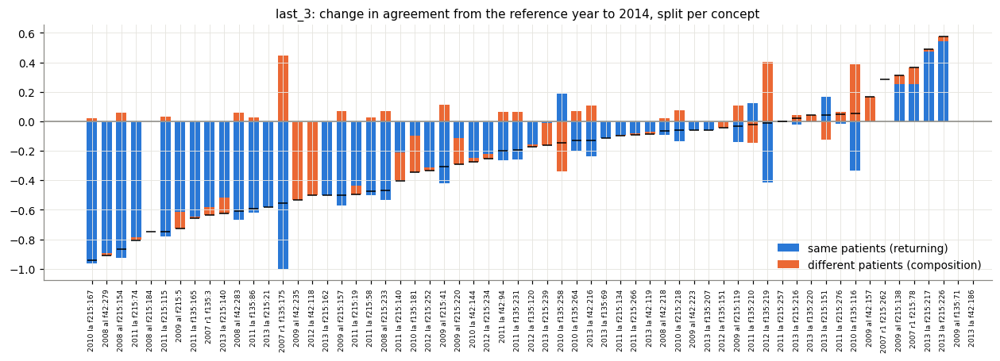

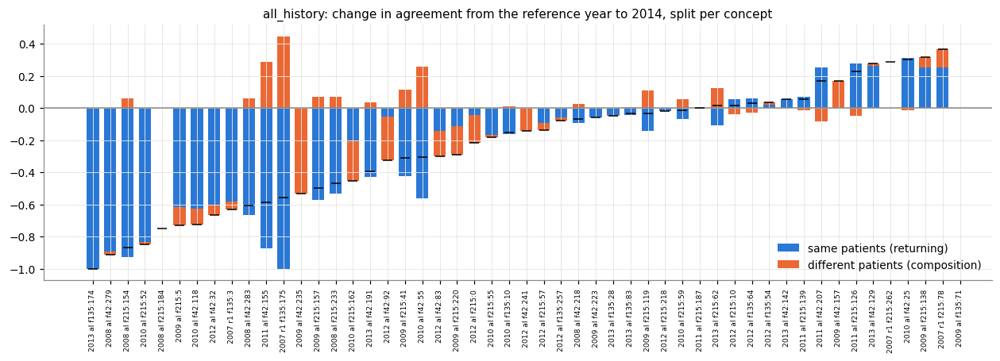

In [18]:
SPLIT_KEYS = {"agreement": "concept|agreement", "activation rate": "concept|activation_rate",
              "rule F2": "concept|rule_f2",
              "absolute sensitivity": f"influence|{paths.PRIMARY_ESTIMATOR}|absolute_sensitivity",
              "signed sensitivity": f"influence|{paths.PRIMARY_ESTIMATOR}|signed_sensitivity",
              "TCAV": f"influence|{paths.PRIMARY_ESTIMATOR}|tcav",
              "absolute sensitivity (legacy)": "influence|legacy|absolute_sensitivity",
              "mean activation": "group|mean_activation"}
split = tables.split_table(cav_records, SPLIT_KEYS, groups=("A", "R"))
split.to_csv(paths.OUTPUT / "composition_split.csv", index=False)
last_pair = split[(split.measure == "agreement") & (split.start == split.reference) & (split.end == paths.LAST_OUTCOME_YEAR)]
for variant in paths.VARIANTS:
    part = last_pair[last_pair.variants.str.contains(variant)].sort_values("total")
    fig, ax = plt.subplots(figsize=(14, 3.8))
    plots.stacked_split(ax, [label[c] for c in part.concept], part.returning.to_numpy(), part.composition.to_numpy(),
                        title=f"{variant}: change in agreement from the reference year to 2014, split per concept")
    ax.plot(np.arange(len(part)), part.total, "k_", ms=8, label="total change")
    plt.show()

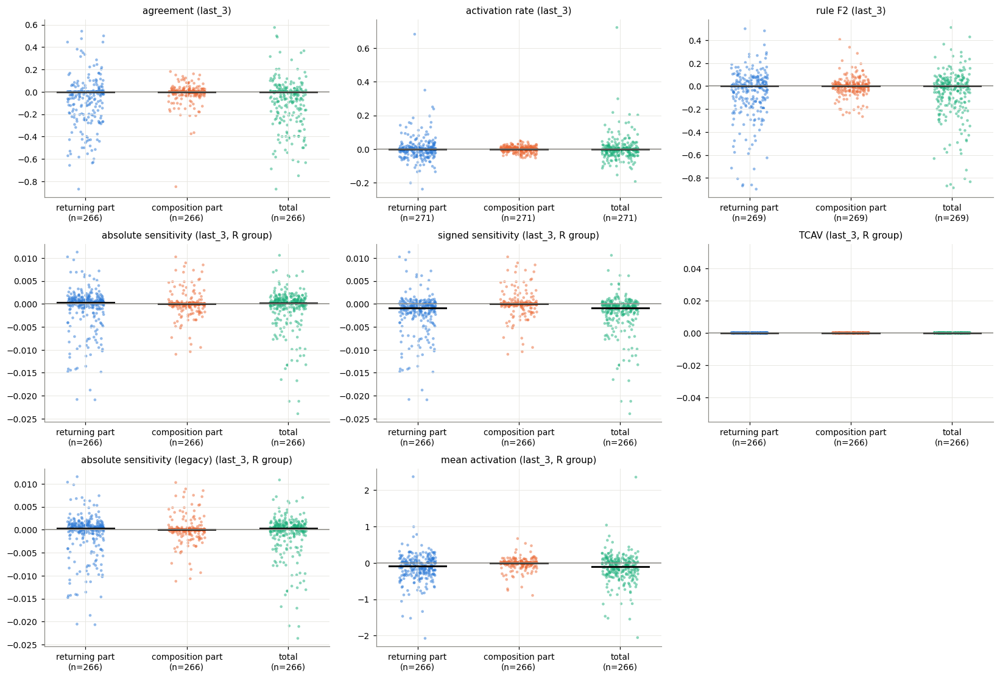

In [19]:
consecutive = split[split.consecutive]
fig, axes = plots.grid(len(SPLIT_KEYS), columns=3, width=5, height=3.4)
for ax, name in zip(axes, SPLIT_KEYS):
    part = consecutive[(consecutive.measure == name) & consecutive.group.isin(["concept", "R"])
                       & consecutive.variants.str.contains("last_3")]
    plots.strip(ax, {"returning part": part.returning, "composition part": part.composition, "total": part.total},
                title=f"{name} (last_3{'' if part.group.eq('concept').all() else ', R group'})")
fig.tight_layout()
plt.show()

In [20]:
summary = []
for name, key in SPLIT_KEYS.items():
    for variant in paths.VARIANTS:
        for group in ((None,) if key.startswith("concept|") else ("A", "R")):
            rows, values = tables.split_replicates(cav_records, key, group)
            keep = rows.variants.str.contains(variant).to_numpy()
            concepts = rows.concept.to_numpy()[keep]
            parts = {"total": values[:, keep, 0], "returning": values[:, keep, 1],
                     "composition": values[:, keep, 0] - values[:, keep, 1]}
            total = values[0, keep, 0]
            defined = np.isfinite(total)
            row = {"measure": name, "variant": variant, "group": group or "concept", "concept-pairs": int(keep.sum()),
                   "defined pairs": int(defined.sum())}
            for part_name, value in parts.items():
                for statistic, function in (("median", tables.median_with_interval), ("mean", tables.mean_with_interval)):
                    point_value, low, high = function(value, concepts)
                    row[f"{statistic} {part_name}"] = point_value
                    row[f"{statistic} {part_name} interval"] = f"[{low:.4g}, {high:.4g}]"
            row["share of pairs with a decline"] = float(np.mean(total[defined] < 0))
            row["share of pairs with no change"] = float(np.mean(total[defined] == 0))
            share = np.abs(parts["returning"]) / (np.abs(parts["returning"]) + np.abs(parts["composition"]))
            row["median share of |change| from returning patients"] = tables.median_with_interval(share)[0]
            summary.append(row)
split_summary = pd.DataFrame(summary)
display(split_summary)

,measure,variant,group,concept-pairs,defined pairs,median total,median total interval,mean total,mean total interval,median returning,median returning interval,mean returning,mean returning interval,median composition,median composition interval,mean composition,mean composition interval,share of pairs with a decline,share of pairs with no change,median share of |change| from returning patients
0,agreement,last_3,concept,271,266,0.0000e+00,"[-0.03848, 0]",-0.0789,"[-0.1043, -0.05533]",0.0000e+00,"[-0.02779, 0]",-0.0693,"[-0.09748, -0.04225]",0.0000e+00,"[0, 0]",-9.6366e-03,"[-0.02521, 0.006575]",0.4850,0.2820,0.8437
1,agreement,all_history,concept,241,239,0.0000e+00,"[-0.004423, 0]",-0.0623,"[-0.08867, -0.03723]",0.0000e+00,"[0, 0]",-0.0526,"[-0.0823, -0.02219]",0.0000e+00,"[0, 0]",-9.6916e-03,"[-0.03318, 0.007971]",0.4059,0.3515,0.8065
2,activation rate,last_3,concept,271,271,0.0000e+00,"[-0.006587, 0]",0.0013,"[-0.009693, 0.01322]",0.0000e+00,"[-0.004696, 0]",0.0025,"[-0.008718, 0.0149]",0.0000e+00,"[0, 0.0006869]",-1.1789e-03,"[-0.004413, 0.001787]",0.4982,0.1697,0.7491
3,activation rate,all_history,concept,241,241,0.0000e+00,"[-0.002604, 0]",0.0076,"[-0.004613, 0.02071]",0.0000e+00,"[0, 0]",0.0087,"[-0.004428, 0.02153]",0.0000e+00,"[-0.0002258, 0]",-1.0049e-03,"[-0.003939, 0.002107]",0.4523,0.1826,0.7008
4,rule F2,last_3,concept,271,269,0.0000e+00,"[-0.02056, 0]",-0.0591,"[-0.08084, -0.03809]",0.0000e+00,"[-0.01798, 0]",-0.0574,"[-0.08153, -0.03115]",0.0000e+00,"[0, 0]",-1.7643e-03,"[-0.02041, 0.01342]",0.4833,0.1673,0.7651
5,rule F2,all_history,concept,241,241,0.0000e+00,"[-0.01337, 0]",-0.0470,"[-0.06831, -0.02807]",0.0000e+00,"[-0.009554, 0]",-0.0417,"[-0.06834, -0.01293]",0.0000e+00,"[0, 0]",-5.2268e-03,"[-0.03143, 0.01205]",0.4689,0.2033,0.7617
6,absolute sensitivity,last_3,A,271,213,3.3654e-05,"[-0.0002916, 0.0003969]",-0.0007,"[-0.001617, -2.769e-05]",4.0584e-05,"[-0.0001618, 0.0004866]",-0.0006,"[-0.001742, 0.0002672]",-2.7491e-05,"[-0.0001229, 0]",-1.0905e-04,"[-0.000833, 0.0005425]",0.4883,0.0000,0.7192
7,absolute sensitivity,last_3,R,271,266,2.4199e-04,"[-0.000102, 0.0005655]",-0.0009,"[-0.001701, -0.0001982]",3.4687e-04,"[-9.253e-06, 0.0006497]",-0.0009,"[-0.001852, -6.574e-05]",0.0000e+00,"[0, 0]",-1.0752e-05,"[-0.000581, 0.0005962]",0.4436,0.0000,0.8353
8,absolute sensitivity,all_history,A,241,186,3.3470e-05,"[-0.0003032, 0.0003219]",-0.0006,"[-0.001136, -5.345e-05]",8.2118e-05,"[-0.0001637, 0.0004694]",-0.0005,"[-0.001373, 0.0003432]",0.0000e+00,"[-0.0001079, 8.425e-06]",-8.6491e-05,"[-0.0007458, 0.0005975]",0.4892,0.0000,0.6775
9,absolute sensitivity,all_history,R,241,239,2.3721e-04,"[-0.0001009, 0.0004849]",-0.0007,"[-0.001426, -7.948e-05]",2.9036e-04,"[-2.738e-05, 0.0005381]",-0.0007,"[-0.001617, 4.771e-05]",0.0000e+00,"[0, 0]",5.1722e-05,"[-0.0005274, 0.0004776]",0.4184,0.0000,0.8542


### 5c. Same patients: rule patients who stopped activating the factor versus those who kept activating
Among patients in R in both consecutive years and in A in the first: change in sensitivity for those who
left A (A 1→0) minus those who stayed in A (A 1→1). Primary estimator, last_3 concepts; one row per
concept-year pair with both groups present. Medians over concept-pairs resample concepts and patients.

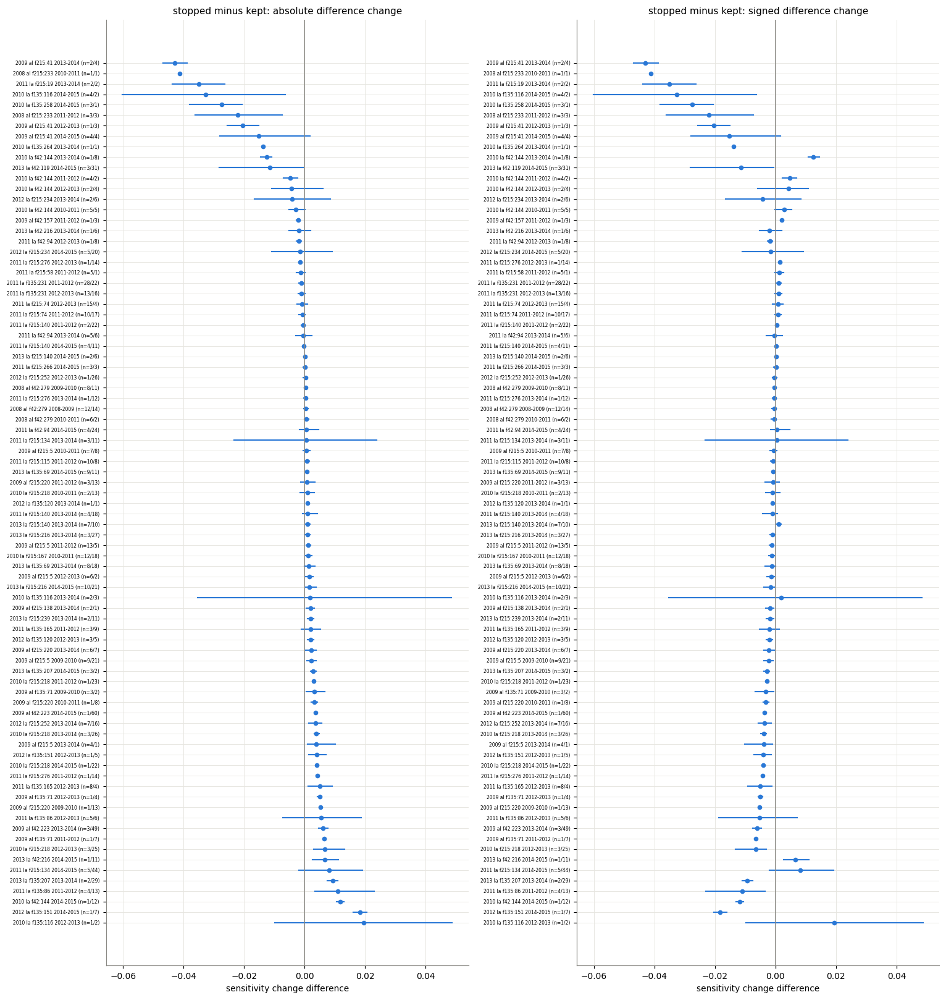

Median over concept-pairs of the absolute-sensitivity difference (stopped - kept): 0.000928 [-0.000144, 0.00204], 83 concept-pairs


In [21]:
transition_rows, transition_replicates = tables.transition_table(last3_records)
transition_concepts = transition_rows.concept.to_numpy()
transitions = transition_rows.sort_values("absolute_difference")
fig, axes = plt.subplots(1, 2, figsize=(14, 0.16 * len(transitions) + 1.5))
for ax, metric in zip(axes, ("absolute_difference", "signed_difference")):
    plots.forest(ax, [f"{label[c]} {s}-{e} (n={a}/{b})" for c, s, e, a, b in
                      transitions[["concept", "start", "end", "stopped_n", "kept_n"]].itertuples(index=False)],
                 transitions[metric].to_numpy(), transitions[f"{metric}_low"].to_numpy(),
                 transitions[f"{metric}_high"].to_numpy(),
                 colours=[plots.VARIANT_COLOURS["last_3" if "last_3" in v else "all_history"] for v in transitions.variants],
                 title=f"stopped minus kept: {metric.replace('_', ' ')} change", xlabel="sensitivity change difference")
    ax.tick_params(axis="y", labelsize=5)
fig.tight_layout()
plt.show()
stopped_kept = tables.median_with_interval(transition_replicates, transition_concepts)
print(f"Median over concept-pairs of the absolute-sensitivity difference (stopped - kept): "
      f"{stopped_kept[0]:.3g} [{stopped_kept[1]:.3g}, {stopped_kept[2]:.3g}], {len(transitions)} concept-pairs")

Same comparison on the log-odds scale, next to the predicted-risk change of the two groups. If the stopped
patients' probability-scale sensitivity rises only because their predicted risk rises, the log-odds version
should be near zero and the probability-scale difference should follow the risk difference across pairs.

,stopped minus kept: change in,median over concept-pairs,low,high,share of pairs above zero,concept-pairs
0,"absolute sensitivity, probability scale",0.0009,-0.0001,0.0020,0.6627,83
1,"absolute sensitivity, log-odds scale",-0.0078,-0.0139,0.0012,0.3614,83
2,predicted risk,0.0055,-0.0001,0.0119,0.6747,83
3,factor activation,-0.4694,-0.7139,-0.2999,0.0361,83


probability scale: rank r of the risk difference with the absolute-sensitivity difference across concept-pairs = 0.92 [0.80, 0.98]


log-odds scale: rank r of the risk difference with the absolute-sensitivity difference across concept-pairs = -0.77 [-0.90, -0.57]


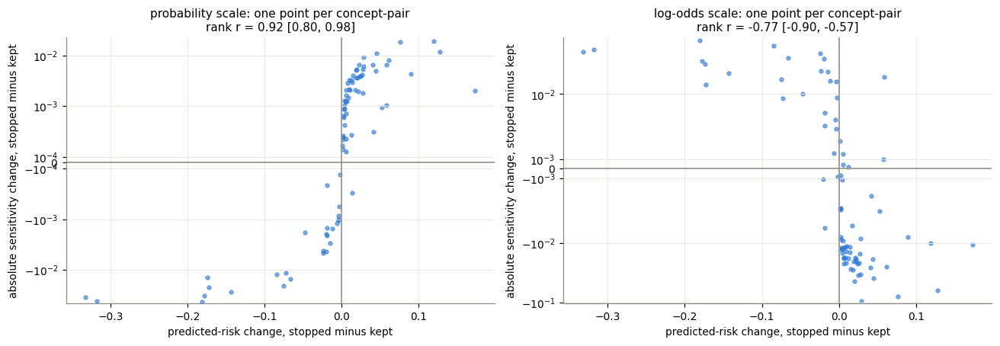

In [22]:
logit_rows, logit_transition_replicates = tables.transition_table(last3_records, paths.LOGIT_ESTIMATOR)
risk_rows, risk_transition_replicates = tables.transition_table(last3_records, replicate_name="risk_difference")
activation_rows, activation_transition_replicates = tables.transition_table(last3_records, replicate_name="activation_difference")
for other in (logit_rows, risk_rows, activation_rows):
    assert other[["concept", "start", "end"]].equals(transition_rows[["concept", "start", "end"]])
stopped_kept_logit = tables.median_with_interval(logit_transition_replicates, transition_concepts)
stopped_kept_risk = tables.median_with_interval(risk_transition_replicates, transition_concepts)
rows = []
for name, values in (("absolute sensitivity, probability scale", transition_replicates),
                     ("absolute sensitivity, log-odds scale", logit_transition_replicates),
                     ("predicted risk", risk_transition_replicates),
                     ("factor activation", activation_transition_replicates)):
    value, low, high = tables.median_with_interval(values, transition_concepts)
    rows.append({"stopped minus kept: change in": name, "median over concept-pairs": value, "low": low, "high": high,
                 "share of pairs above zero": float(np.mean(values[0] > 0)), "concept-pairs": values.shape[1]})
display(pd.DataFrame(rows))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, (values, name) in zip(axes, ((transition_replicates, "probability scale"), (logit_transition_replicates, "log-odds scale"))):
    r = associations.summarize(associations.correlation(risk_transition_replicates, values, transition_concepts))
    print(f"{name}: rank r of the risk difference with the absolute-sensitivity difference across concept-pairs = "
          f"{r['r']:.2f} [{r['low']:.2f}, {r['high']:.2f}]")
    ax.scatter(risk_transition_replicates[0], values[0], s=10, alpha=0.6, color=plots.BLUE)
    ax.axhline(0, color=plots.GREY, lw=1)
    ax.axvline(0, color=plots.GREY, lw=1)
    ax.set(xlabel="predicted-risk change, stopped minus kept", ylabel=f"absolute sensitivity change, stopped minus kept",
           title=f"{name}: one point per concept-pair\nrank r = {r['r']:.2f} [{r['low']:.2f}, {r['high']:.2f}]")
    ax.set_yscale("symlog", linthresh=np.nanpercentile(np.abs(values[0]), 25))
fig.tight_layout()
plt.show()

### 5d. Across families: does agreement change among the same patients go with influence change among them?
last_3 concepts, consecutive year pairs; correlations across concept-pairs resample concepts and patients.

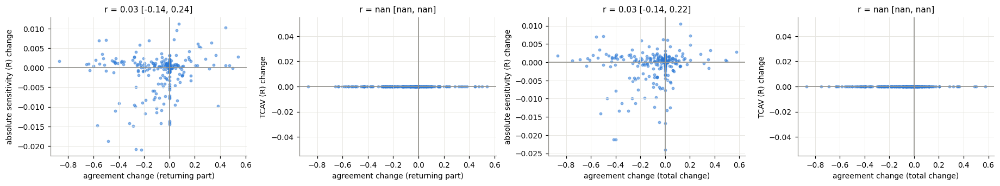

,part,influence,r,replicate_median,low,high,undefined_share
0,returning part,absolute sensitivity (R),0.0334,0.0491,-0.1445,0.2370,0.0
1,returning part,TCAV (R),NaN,NaN,NaN,NaN,1.0
2,total change,absolute sensitivity (R),0.0315,0.0484,-0.1406,0.2223,0.0
3,total change,TCAV (R),NaN,NaN,NaN,NaN,1.0


In [23]:
rows_a, agreement_split = tables.split_replicates(last3_records, "concept|agreement")
rows_s, sensitivity_split = tables.split_replicates(last3_records, f"influence|{paths.PRIMARY_ESTIMATOR}|absolute_sensitivity", "R")
rows_t, tcav_split = tables.split_replicates(last3_records, f"influence|{paths.PRIMARY_ESTIMATOR}|tcav", "R")
for other in (rows_s, rows_t):
    assert rows_a[["concept", "start", "end"]].equals(other[["concept", "start", "end"]])
pair_concepts = rows_a.concept.to_numpy()
results = []
fig, axes = plots.grid(4, columns=4, width=4.2)
for k, (part_index, part_name) in enumerate(((1, "returning part"), (0, "total change"))):
    for j, (other, other_name) in enumerate(((sensitivity_split, "absolute sensitivity (R)"), (tcav_split, "TCAV (R)"))):
        x, y = agreement_split[:, :, part_index], other[:, :, part_index]
        r = associations.summarize(associations.correlation(x, y, pair_concepts))
        results.append({"part": part_name, "influence": other_name, **r})
        ax = axes[2 * k + j]
        ax.scatter(x[0], y[0], s=8, alpha=0.5, color=plots.BLUE)
        ax.axhline(0, color=plots.GREY, lw=1)
        ax.axvline(0, color=plots.GREY, lw=1)
        ax.set(xlabel=f"agreement change ({part_name})", ylabel=f"{other_name} change",
               title=f"r = {r['r']:.2f} [{r['low']:.2f}, {r['high']:.2f}]")
fig.tight_layout()
plt.show()
display(pd.DataFrame(results))

Risk check for 5d: the same correlations with the log-odds-scale sensitivity, and with the R group's
predicted-risk change (same part) removed as a control.

In [24]:
rows_l, logit_split = tables.split_replicates(last3_records, f"influence|{paths.LOGIT_ESTIMATOR}|absolute_sensitivity", "R")
rows_r, risk_split = tables.split_replicates(last3_records, "group|mean_risk", "R")
for other in (rows_l, rows_r):
    assert rows_a[["concept", "start", "end"]].equals(other[["concept", "start", "end"]])
returning_checks = []
for part_index, part_name in ((1, "returning part"), (0, "total change")):
    x, risk = agreement_split[:, :, part_index], risk_split[:, :, part_index]
    returning_checks.append({"part": part_name, "compared with": "predicted risk (R)", "controls": "none",
                             **associations.summarize(associations.correlation(x, risk, pair_concepts))})
    for name, other in (("absolute sensitivity (R)", sensitivity_split), ("absolute sensitivity, log-odds (R)", logit_split)):
        y = other[:, :, part_index]
        returning_checks.append({"part": part_name, "compared with": name, "controls": "none",
                                 **associations.summarize(associations.correlation(x, y, pair_concepts))})
        returning_checks.append({"part": part_name, "compared with": name, "controls": "predicted-risk change",
                                 **associations.summarize(associations.correlation(x, y, pair_concepts, [risk]))})
returning_checks = pd.DataFrame(returning_checks)
display(returning_checks)

,part,compared with,controls,r,replicate_median,low,high,undefined_share
0,returning part,predicted risk (R),none,0.0747,0.0893,-0.0985,0.2714,0.0
1,returning part,absolute sensitivity (R),none,0.0334,0.0491,-0.1445,0.2370,0.0
2,returning part,absolute sensitivity (R),predicted-risk change,-0.0644,-0.0612,-0.2265,0.1022,0.0
3,returning part,"absolute sensitivity, log-odds (R)",none,0.0033,0.0080,-0.1673,0.1792,0.0
4,returning part,"absolute sensitivity, log-odds (R)",predicted-risk change,0.0518,0.0732,-0.0897,0.2232,0.0
5,total change,predicted risk (R),none,0.0999,0.0896,-0.0925,0.2741,0.0
6,total change,absolute sensitivity (R),none,0.0315,0.0484,-0.1406,0.2223,0.0
7,total change,absolute sensitivity (R),predicted-risk change,-0.1113,-0.0696,-0.2382,0.0990,0.0
8,total change,"absolute sensitivity, log-odds (R)",none,-0.0024,0.0040,-0.1604,0.1686,0.0
9,total change,"absolute sensitivity, log-odds (R)",predicted-risk change,0.0601,0.0638,-0.0883,0.2145,0.0


## Step 6 — Concepts and influence versus same-year performance

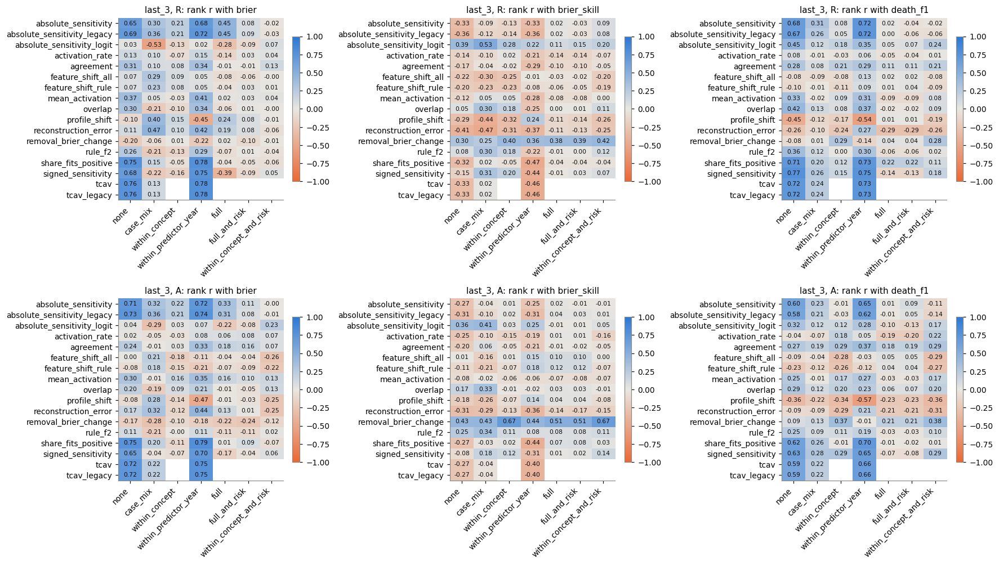

In [25]:
SAME_YEAR_FEATURES = ["agreement", "rule_f2", "overlap", "activation_rate", "mean_activation", "profile_shift",
                      "reconstruction_error", "signed_sensitivity", "absolute_sensitivity", "tcav",
                      "share_fits_positive", "absolute_sensitivity_legacy", "tcav_legacy", "absolute_sensitivity_logit",
                      "removal_brier_change", "feature_shift_all", "feature_shift_rule"]
TARGETS = ["brier", "brier_skill", "death_f1"]
cells = []
for variant in paths.VARIANTS:
    for group in ("A", "R"):
        mask = variant_mask[variant] & group_mask[group] & outcome_mask
        for feature in SAME_YEAR_FEATURES:
            for target in TARGETS:
                for adjustment in associations.ADJUSTMENTS:
                    cells.append({"variant": variant, "group": group, "feature": feature, "target": target,
                                  "controls": adjustment, "mask": mask})
same_year = associations.grid(point, cube, cells)
same_year.to_csv(paths.OUTPUT / "same_year_performance.csv", index=False)
fig, axes = plots.grid(6, columns=3, width=5.4, height=4.6)
for ax, (group, target) in zip(axes, [(g, t) for g in ("R", "A") for t in TARGETS]):
    part = same_year[(same_year.variant == "last_3") & (same_year.group == group) & (same_year.target == target)]
    matrix = part.pivot(index="feature", columns="adjustment", values="r")[list(associations.ADJUSTMENTS)]
    plots.heatmap(ax, matrix.to_numpy(), matrix.index, matrix.columns, diverging=True, limit=1,
                  title=f"last_3, {group}: rank r with {target}")
fig.tight_layout()
plt.show()

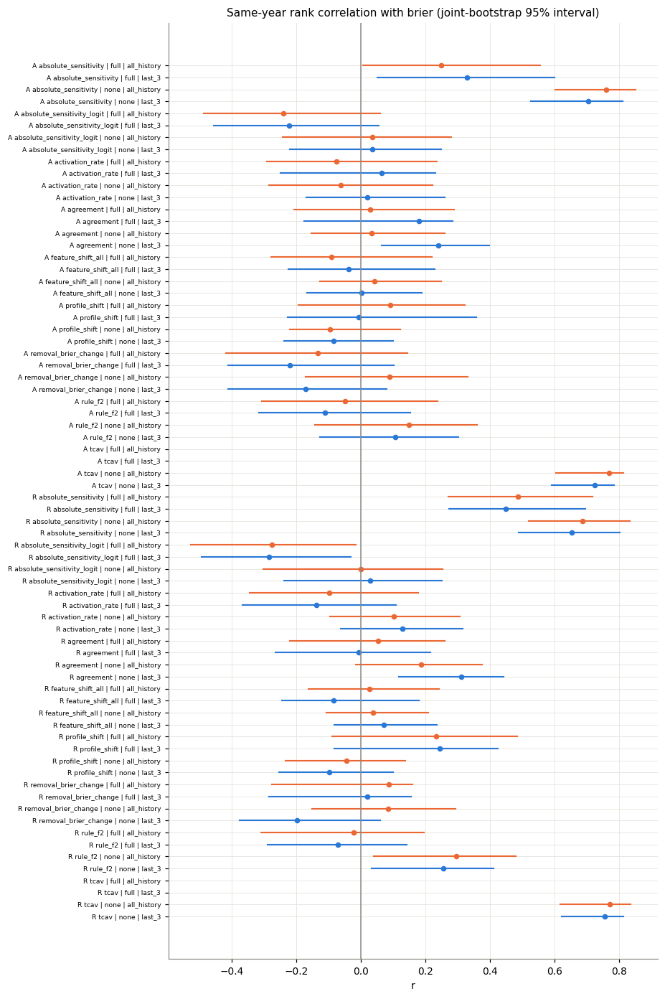

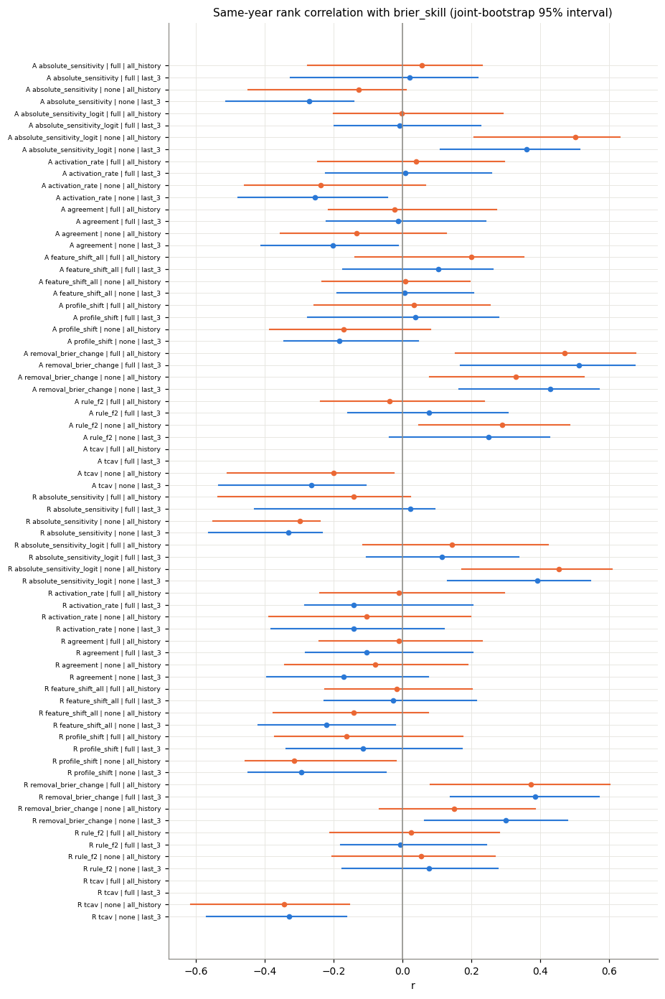

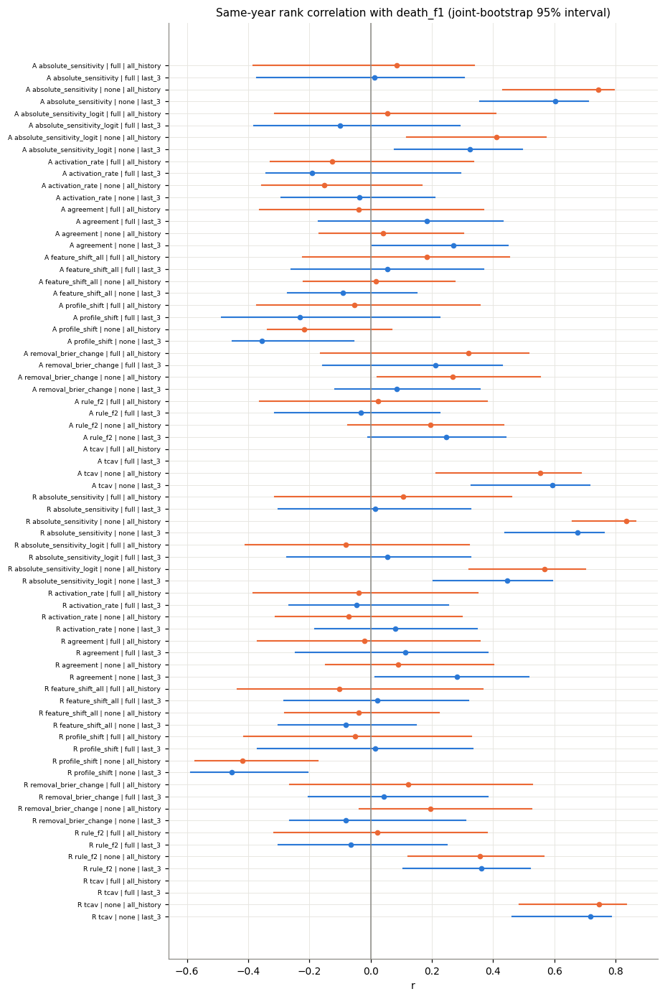

In [26]:
focus = same_year[(same_year.adjustment.isin(["none", "full"])) & same_year.feature.isin(
    ["agreement", "rule_f2", "activation_rate", "profile_shift", "absolute_sensitivity", "absolute_sensitivity_logit",
     "tcav", "removal_brier_change", "feature_shift_all"])]
for target in TARGETS:
    part = focus[focus.target == target].sort_values(["group", "feature", "adjustment", "variant"])
    fig, ax = plt.subplots(figsize=(8, 0.2 * len(part) + 1))
    plots.forest(ax, [f"{r.group} {r.feature} | {r.adjustment} | {r.variant}" for r in part.itertuples()],
                 part.r.to_numpy(), part.low.to_numpy(), part.high.to_numpy(),
                 colours=[plots.VARIANT_COLOURS[v] for v in part.variant],
                 title=f"Same-year rank correlation with {target} (joint-bootstrap 95% interval)", xlabel="r")
    ax.tick_params(axis="y", labelsize=6)
    plt.show()

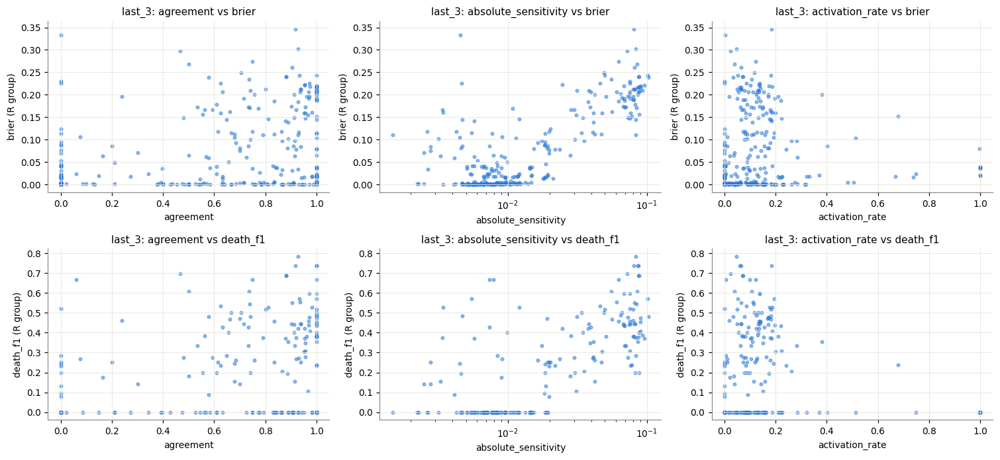

In [27]:
fig, axes = plots.grid(6, columns=3, width=4.6)
part = point[variant_mask["last_3"] & group_mask["R"] & outcome_mask]
for ax, (feature, target) in zip(axes, [(f, t) for t in ("brier", "death_f1") for f in ("agreement", "absolute_sensitivity", "activation_rate")]):
    ax.scatter(part[feature], part[target], s=9, alpha=0.5, color=plots.BLUE)
    ax.set(xlabel=feature, ylabel=f"{target} (R group)", title=f"last_3: {feature} vs {target}")
    if feature == "absolute_sensitivity":
        ax.set_xscale("log")
fig.tight_layout()
plt.show()

**Removal-effect check.** The removal effect and Brier use the same patients' outcomes. Per patient, with p the
prediction, q the prediction after removing the factor and y the outcome, the removal effect splits exactly:
(q − y)² − (p − y)² = (q² − p²) − 2y(q − p). The first part uses no outcomes; the second comes only from deaths.
If only the death part goes with Brier and Brier skill, the link is a by-product of the shared outcomes.
`removal_risk_change` (mean q − p) is a second outcome-free view.

largest |removal effect - (outcome-free part + death part)| over all rows and replicates: 1.2e-08


adjustment                                                                none                 full         full_and_risk
target      variant     group feature                                                                                    
brier       all_history A     removal_brier_change          0.09 [-0.17, 0.33]  -0.13 [-0.42, 0.14]   -0.14 [-0.43, 0.12]
                              removal_brier_death_part      0.35 [-0.09, 0.61]  -0.47 [-0.64, 0.01]  -0.47 [-0.67, -0.00]
                              removal_brier_outcome_free  -0.40 [-0.63, -0.02]   0.21 [-0.15, 0.51]    0.17 [-0.15, 0.42]
                              removal_risk_change         -0.48 [-0.69, -0.13]   0.15 [-0.14, 0.44]    0.09 [-0.19, 0.37]
                        R     removal_brier_change          0.08 [-0.15, 0.29]   0.09 [-0.28, 0.16]    0.02 [-0.35, 0.10]
                              removal_brier_death_part      0.34 [-0.03, 0.63]   0.08 [-0.49, 0.17]   -0.03 [-0.66, 0.11]
                              removal_brier_outcome_free  -0.42 [-0.65, -0.09]   0.09 [-0.23, 0.46]    0.00 [-0.20, 0.34]
                              removal_risk_change         -0.48 [-0.68, -0.15]  -0.09 [-0.33, 0.33]   -0.04 [-0.25, 0.29]
            last_3      A     removal_brier_change         -0.17 [-0.41, 0.08]  -0.22 [-0.41, 0.10]   -0.24 [-0.43, 0.07]
                              removal_brier_death_part      0.35 [-0.02, 0.60]  -0.12 [-0.47, 0.12]   -0.14 [-0.53, 0.10]
                              removal_brier_outcome_free  -0.39 [-0.58, -0.06]   0.20 [-0.09, 0.53]    0.15 [-0.10, 0.43]
                              removal_risk_change         -0.44 [-0.62, -0.13]   0.17 [-0.09, 0.47]    0.11 [-0.12, 0.39]
                        R     removal_brier_change         -0.20 [-0.38, 0.06]   0.02 [-0.29, 0.15]   -0.10 [-0.37, 0.05]
                              removal_brier_death_part       0.34 [0.03, 0.61]   0.12 [-0.35, 0.22]    0.02 [-0.47, 0.14]
                              removal_brier_outcome_free  -0.38 [-0.59, -0.08]   0.13 [-0.19, 0.44]    0.03 [-0.17, 0.30]
                              removal_risk_change         -0.44 [-0.63, -0.17]   0.03 [-0.28, 0.33]    0.04 [-0.20, 0.28]
brier_skill all_history A     removal_brier_change           0.33 [0.08, 0.53]    0.47 [0.15, 0.68]     0.47 [0.16, 0.69]
                              removal_brier_death_part      0.10 [-0.09, 0.27]    0.72 [0.40, 0.85]     0.73 [0.40, 0.85]
                              removal_brier_outcome_free    0.09 [-0.10, 0.32]  -0.02 [-0.27, 0.23]   -0.03 [-0.30, 0.23]
                              removal_risk_change           0.15 [-0.04, 0.42]   0.01 [-0.27, 0.21]   -0.01 [-0.27, 0.20]
                        R     removal_brier_change          0.15 [-0.07, 0.39]    0.37 [0.08, 0.60]     0.39 [0.13, 0.64]
                              removal_brier_death_part     -0.02 [-0.25, 0.12]    0.25 [0.09, 0.72]     0.27 [0.12, 0.77]
                              removal_brier_outcome_free    0.18 [-0.05, 0.41]   0.02 [-0.39, 0.25]    0.03 [-0.33, 0.24]
                              removal_risk_change           0.23 [-0.00, 0.47]   0.08 [-0.33, 0.32]    0.07 [-0.32, 0.29]
            last_3      A     removal_brier_change           0.43 [0.16, 0.57]    0.51 [0.17, 0.67]     0.51 [0.18, 0.67]
                              removal_brier_death_part      0.01 [-0.16, 0.20]    0.61 [0.26, 0.77]     0.61 [0.26, 0.77]
                              removal_brier_outcome_free    0.09 [-0.11, 0.31]  -0.03 [-0.31, 0.15]   -0.04 [-0.32, 0.16]
                              removal_risk_change           0.15 [-0.03, 0.35]  -0.11 [-0.34, 0.13]   -0.12 [-0.33, 0.14]
                        R     removal_brier_change           0.30 [0.07, 0.48]    0.38 [0.14, 0.57]     0.39 [0.18, 0.60]
                              removal_brier_death_part     -0.02 [-0.23, 0.12]    0.21 [0.02, 0.59]     0.21 [0.05, 0.63]
                              removal_brier_outcome_free    0.11 [-0.11, 0.32]   0.03 [-0.34, 0.

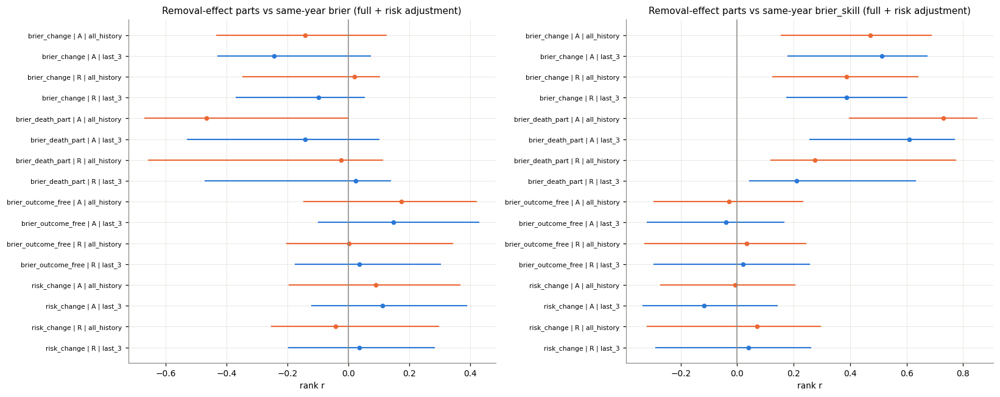

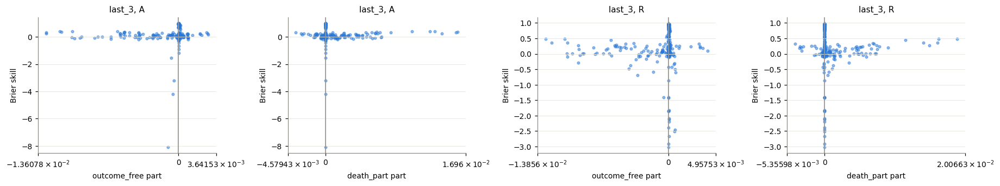

In [28]:
REMOVAL_PARTS = ["removal_brier_change", "removal_brier_outcome_free", "removal_brier_death_part", "removal_risk_change"]
gap = np.nanmax(np.abs(cube["removal_brier_change"] - cube["removal_brier_outcome_free"] - cube["removal_brier_death_part"]))
print(f"largest |removal effect - (outcome-free part + death part)| over all rows and replicates: {gap:.2g}")
cells = []
for variant in paths.VARIANTS:
    for group in ("A", "R"):
        mask = variant_mask[variant] & group_mask[group] & outcome_mask
        for feature in REMOVAL_PARTS:
            for target in ("brier", "brier_skill"):
                for adjustment in ("none", "full", "full_and_risk"):
                    cells.append({"variant": variant, "group": group, "feature": feature, "target": target,
                                  "controls": adjustment, "mask": mask})
removal_check = associations.grid(point, cube, cells)
removal_check.to_csv(paths.OUTPUT / "removal_check.csv", index=False)
removal_check["value"] = [f"{r:.2f} [{low:.2f}, {high:.2f}]" for r, low, high in
                          removal_check[["r", "low", "high"]].itertuples(index=False)]
with pd.option_context("display.width", 220, "display.max_rows", 100):
    display(removal_check.pivot_table(index=["target", "variant", "group", "feature"], columns="adjustment",
                                      values="value", aggfunc="first")[["none", "full", "full_and_risk"]])
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, target in zip(axes, ("brier", "brier_skill")):
    part = removal_check[(removal_check.target == target) & (removal_check.adjustment == "full_and_risk")]
    part = part.sort_values(["feature", "group", "variant"])
    plots.forest(ax, [f"{r.feature.replace('removal_', '')} | {r.group} | {r.variant}" for r in part.itertuples()],
                 part.r.to_numpy(), part.low.to_numpy(), part.high.to_numpy(),
                 colours=[plots.VARIANT_COLOURS[v] for v in part.variant],
                 title=f"Removal-effect parts vs same-year {target} (full + risk adjustment)", xlabel="rank r")
    ax.tick_params(axis="y", labelsize=7)
fig.tight_layout()
plt.show()

part = point[variant_mask["last_3"] & outcome_mask]
fig, axes = plots.grid(4, columns=4, width=4.2)
for ax, (group, feature) in zip(axes, [(g, f) for g in ("A", "R") for f in ("removal_brier_outcome_free", "removal_brier_death_part")]):
    rows = part[part.group == group]
    ax.scatter(rows[feature], rows.brier_skill, s=9, alpha=0.5, color=plots.BLUE)
    ax.axvline(0, color=plots.GREY, lw=1)
    ax.set(xlabel=feature.replace("removal_brier_", "") + " part", ylabel="Brier skill", title=f"last_3, {group}",
           xscale="symlog")
fig.tight_layout()
plt.show()

**Four agreement groups.** Does loss concentrate in rule patients who no longer activate the factor (R+A−)?
Median across concepts by years since reference, pooled over the reference years of each variant (a point at
k years mixes predictors from different references), with intervals that resample concepts and patients.

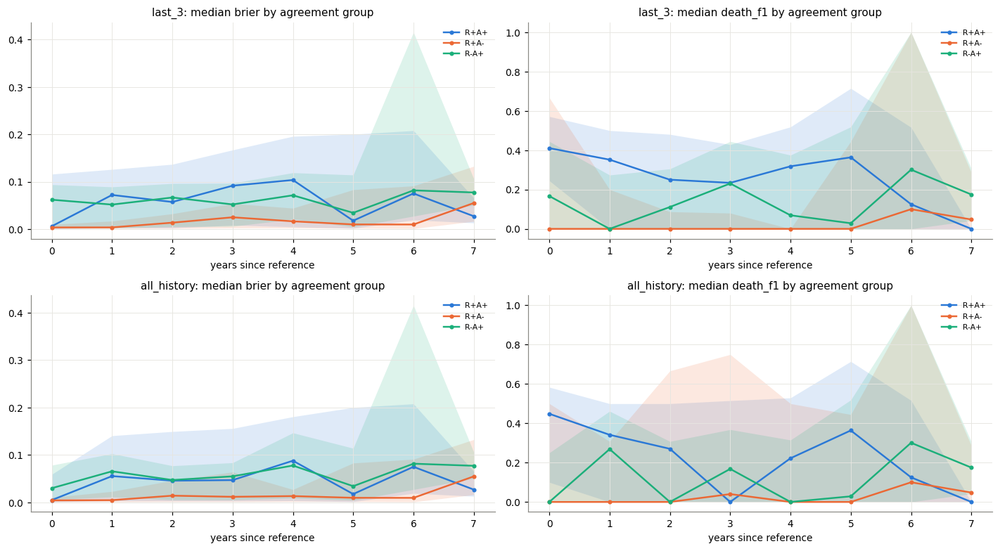

In [29]:
fig, axes = plots.grid(4, columns=2, width=6.5, height=3.6)
for row, variant in enumerate(paths.VARIANTS):
    for col, metric in enumerate(("brier", "death_f1")):
        ax = axes[2 * row + col]
        for colour, group in zip(plots.SERIES, ("R+A+", "R+A-", "R-A+")):
            rows, values = tables.stacked_measure(cav_records, f"group|{metric}", group)
            rows["since"] = rows.year - rows.reference
            keep_variant = rows.variants.str.contains(variant).to_numpy() & (rows.year <= paths.LAST_OUTCOME_YEAR).to_numpy()
            line = []
            for since in sorted(rows.since[keep_variant].unique()):
                at = keep_variant & (rows.since == since).to_numpy()
                line.append((since, *tables.median_with_interval(values[:, at], rows.concept.to_numpy()[at])))
            line = np.array(line)
            plots.band(ax, line[:, 0], line[:, 1], line[:, 2], line[:, 3], colour=colour, label=group)
        ax.set(title=f"{variant}: median {metric} by agreement group", xlabel="years since reference")
        ax.legend(fontsize=7)
fig.tight_layout()
plt.show()

In [30]:
gap_rows = []
for record in cav_records:
    data = measures.load_replicates(record)
    for metric in ("brier", "death_f1"):
        lost = data[f"group|{metric}"][:, measures.GROUPS.index("R+A-")]
        kept = data[f"group|{metric}"][:, measures.GROUPS.index("R+A+")]
        for y, year in enumerate(measures.YEARS):
            if record["reference"] <= year <= paths.LAST_OUTCOME_YEAR:
                gap_rows.append({"concept": record["concept"], "variants": ",".join(record["variants"]), "metric": metric,
                                 "year": year, "difference": lost[0, y] - kept[0, y], "replicates": lost[:, y] - kept[:, y]})
gaps = pd.DataFrame(gap_rows)
for metric in ("brier", "death_f1"):
    for variant in paths.VARIANTS:
        part = gaps[(gaps.metric == metric) & gaps.variants.str.contains(variant)]
        stacked = np.stack(part.replicates.to_numpy(), axis=1)
        point_value, low, high = tables.median_with_interval(stacked, part.concept.to_numpy())
        print(f"{variant} {metric}: median over concept-years of (R+A-) minus (R+A+) = {point_value:.4f} "
              f"[{low:.4f}, {high:.4f}], {np.isfinite(stacked[0]).sum()} defined concept-years")

last_3 brier: median over concept-years of (R+A-) minus (R+A+) = -0.0003 [-0.0160, 0.0006], 178 defined concept-years


all_history brier: median over concept-years of (R+A-) minus (R+A+) = -0.0015 [-0.0080, 0.0007], 147 defined concept-years


last_3 death_f1: median over concept-years of (R+A-) minus (R+A+) = -0.2082 [-0.3636, 0.0000], 72 defined concept-years


all_history death_f1: median over concept-years of (R+A-) minus (R+A+) = -0.1797 [-0.3810, 0.0000], 54 defined concept-years


**Is the pooled R+A− picture consistent across concepts?** Pooled numbers are dominated by large concept-years,
so here each concept-year counts once: how often R+A− is lower than R+A+ on each measure (last_3, reference year
to 2014, the same concept-years as the R−A+ cell below and the recurrence count in Step 6b), and the direction of the recurring features
(positive SMD = more common in R+A−).

178 concept-years with both groups, 61 last_3 concepts; median group size R+A- 6.0, R+A+ 20.5 patients
pooled over these concept-years (a patient counts once per concept): mortality R+A- 0.053, R+A+ 0.118


,R+A- lower,equal,R+A- higher,median difference
mortality,0.433,0.365,0.202,0.000
mean_risk,0.483,0.000,0.517,0.002
brier,0.511,0.000,0.489,-0.000
brier_skill,0.674,0.000,0.326,-0.087


,feature,concept-years defined,median SMD,share positive (of defined)
0,DIAGN_N180,162,0.471,0.636
1,EVENT_C1DIALISE_HD,147,0.392,0.694
2,EVENT_c2MED_ERITRO,162,0.239,0.556
3,EVENT_c2MED_HIDFE,145,0.000,0.497
4,EVENT_c5TX_TX,123,0.192,0.569
5,EVENT_c3ACESSO_FV,135,-0.074,0.489


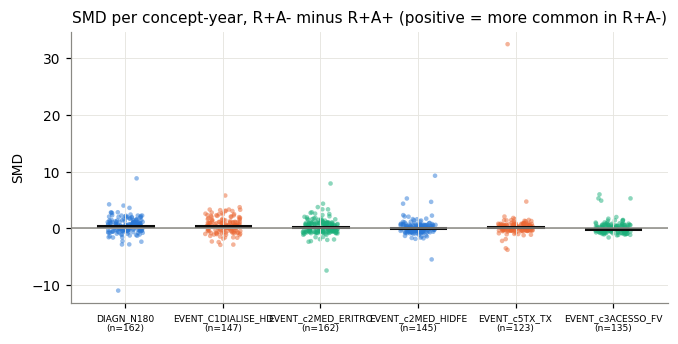

In [31]:
lost, kept = measures.GROUPS.index("R+A-"), measures.GROUPS.index("R+A+")
pair_rows, feature_smd, pooled = [], {}, np.zeros((2, 2))
for record in last3_records:
    data, profile = measures.load_replicates(record), features.load_features(record)
    names = list(profile["feature_names"])
    for y, year in enumerate(measures.YEARS):
        if not record["reference"] <= year <= paths.LAST_OUTCOME_YEAR:
            continue
        if data["group|n"][0, lost, y] == 0 or data["group|n"][0, kept, y] == 0:
            continue
        pair_rows.append({m: data[f"group|{m}"][0, lost, y] - data[f"group|{m}"][0, kept, y]
                          for m in ("mortality", "mean_risk", "brier", "brier_skill")}
                         | {"n R+A-": data["group|n"][0, lost, y], "n R+A+": data["group|n"][0, kept, y]})
        pooled += [[data["group|deaths"][0, g, y], data["group|n"][0, g, y]] for g in (lost, kept)]
        for name in ("DIAGN_N180", "EVENT_C1DIALISE_HD", "EVENT_c2MED_ERITRO", "EVENT_c2MED_HIDFE", "EVENT_c5TX_TX", "EVENT_c3ACESSO_FV"):
            feature_smd.setdefault(name, []).append(profile["smd_stopped_vs_kept"][y][names.index(name)])
pair_rows = pd.DataFrame(pair_rows)
consistency = pd.DataFrame({m: {"R+A- lower": (v < 0).mean(), "equal": (v == 0).mean(), "R+A- higher": (v > 0).mean(),
                                "median difference": v.median()} for m, v in pair_rows.drop(columns=["n R+A-", "n R+A+"]).items()}).T
print(f"{len(pair_rows)} concept-years with both groups, {len(last3_records)} last_3 concepts; median group size "
      f"R+A- {pair_rows['n R+A-'].median():.1f}, R+A+ {pair_rows['n R+A+'].median():.1f} patients")
print(f"pooled over these concept-years (a patient counts once per concept): mortality R+A- {pooled[0, 0] / pooled[0, 1]:.3f}, "
      f"R+A+ {pooled[1, 0] / pooled[1, 1]:.3f}")
display(consistency.round(3))
display(pd.DataFrame([{"feature": name, "concept-years defined": int(np.isfinite(v).sum()), "median SMD": np.nanmedian(v),
                       "share positive (of defined)": float(np.mean(np.asarray(v)[np.isfinite(v)] > 0))}
                      for name, v in feature_smd.items()]).round(3))
fig, ax = plt.subplots(figsize=(7, 3.2))
plots.strip(ax, {name: values for name, values in feature_smd.items()},
            title="SMD per concept-year, R+A- minus R+A+ (positive = more common in R+A-)", ylabel="SMD")
ax.tick_params(axis="x", labelsize=6)
plt.show()

**Who are the activation-only patients (R−A+)?** Patients who activate the factor without matching the rule,
compared with rule patients who activate it (R+A+) and with patients in neither group. Each concept-year counts
once (last_3, up to 2014). Features are ranked by the size of their median SMD; the table lists only features
defined in at least half of the concept-years (a display choice, not a test). "share where a rule feature" says
how often the feature is part of that concept's own rule, where a difference partly follows from the definition.
R+A− versus R+A+ is shown alongside for comparison.

R−A+ vs R+A+: 201 concept-years; median over concept-years of mean |SMD|: all features 0.51, the concept's own rule features 1.45


,feature,concept-years defined,median SMD,share positive,share where a rule feature
0,DIAGN_Z940,142,0.297,0.556,0.239
1,EVENT_C1DIALISE_DP,142,0.270,0.627,0.007
2,EVENT_c3ACESSO_CT,158,-0.240,0.399,0.114
3,EVENT_c2MED_MICOF,130,0.235,0.546,0.023
4,EVENT_c2MED_SEVEL,178,0.210,0.584,0.056
5,EVENT_c2MED_TACRO,132,0.197,0.545,0.030
6,EVENT_c2MED_HIDFE,183,0.185,0.579,0.153
7,EVENT_C1DIALISE_HD,178,-0.171,0.427,0.803
8,DIAGN_N180,176,-0.162,0.460,0.551
9,EVENT_c3ACESSO_FV,166,-0.158,0.416,0.012


R−A+ vs neither: 203 concept-years; median over concept-years of mean |SMD|: all features 0.22, the concept's own rule features 0.71


,feature,concept-years defined,median SMD,share positive,share where a rule feature
0,DIAGN_Z940,203,-0.537,0.296,0.222
1,EVENT_c2MED_MICOF,203,-0.432,0.305,0.020
2,EVENT_c5TX_TX,203,-0.432,0.325,0.039
3,EVENT_c2MED_TACRO,203,-0.354,0.310,0.020
4,EVENT_c2MED_AZA,203,-0.343,0.167,0.010
5,DIAGN_N180,203,0.321,0.655,0.576
6,DIAGN_E780,203,-0.295,0.271,0.000
7,EVENT_c5TX_EXTX,203,-0.282,0.305,0.034
8,EVENT_c2MED_CSA,199,-0.259,0.176,0.000
9,DIAGN_N188,203,-0.197,0.266,0.020


R+A− vs R+A+: 178 concept-years; median over concept-years of mean |SMD|: all features 0.55, the concept's own rule features 0.70


,feature,concept-years defined,median SMD,share positive,share where a rule feature
0,DIAGN_N180,162,0.471,0.636,0.562
1,EVENT_C1DIALISE_HD,147,0.392,0.694,0.741
2,EVENT_c2MED_TACRO,115,0.324,0.617,0.017
3,DIAGN_E780,110,-0.269,0.382,0.000
4,EVENT_c2MED_ERITRO,162,0.239,0.556,0.241
5,DIAGN_N188,132,-0.236,0.432,0.015
6,EVENT_c5TX_EXTX,137,0.233,0.540,0.015
7,EVENT_c2MED_MICOF,110,0.226,0.536,0.036
8,DIAGN_N179,91,-0.224,0.385,0.000
9,EVENT_c5TX_TX,123,0.192,0.569,0.065


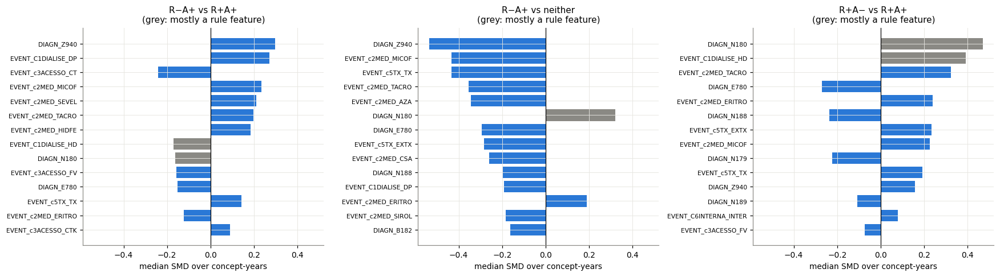

In [32]:
RA_COMPARISONS = {"R−A+ vs R+A+": ("smd_activation_only_vs_both", "R-A+", "R+A+"),
                  "R−A+ vs neither": ("smd_activation_only_vs_neither", "R-A+", "neither"),
                  "R+A− vs R+A+": ("smd_stopped_vs_kept", "R+A-", "R+A+")}
group_profiles = {}
for title, (key, first, second) in RA_COMPARISONS.items():
    smds, rule_flags, overall, overall_rule = [], [], [], []
    for record in last3_records:
        data, profile = measures.load_replicates(record), features.load_features(record)
        is_rule = np.zeros(len(profile["feature_names"]), bool)
        is_rule[profile["rule_columns"]] = True
        for y, year in enumerate(measures.YEARS):
            if year < record["reference"] or year > paths.LAST_OUTCOME_YEAR:
                continue
            if data["group|n"][0, measures.GROUPS.index(first), y] == 0 or data["group|n"][0, measures.GROUPS.index(second), y] == 0:
                continue
            value = profile[key][y]
            smds.append(value)
            rule_flags.append(is_rule)
            overall.append(np.nanmean(np.abs(value)) if np.isfinite(value).any() else np.nan)
            overall_rule.append(np.nanmean(np.abs(value[is_rule])) if np.isfinite(value[is_rule]).any() else np.nan)
    smds, rule_flags = np.array(smds), np.array(rule_flags)
    defined = np.isfinite(smds)
    with np.errstate(all="ignore"):
        table = pd.DataFrame({"feature": profile["feature_names"], "concept-years defined": defined.sum(0),
                              "median SMD": np.nanmedian(np.where(defined, smds, np.nan), 0),
                              "share positive": (defined & (np.nan_to_num(smds) > 0)).sum(0) / np.maximum(defined.sum(0), 1),
                              "share where a rule feature": (rule_flags & defined).sum(0) / np.maximum(defined.sum(0), 1)})
    table = table[table["concept-years defined"] >= len(smds) / 2]
    table = table.reindex(table["median SMD"].abs().sort_values(ascending=False).index).head(14)
    group_profiles[title] = table
    print(f"{title}: {len(smds)} concept-years; median over concept-years of mean |SMD|: all features "
          f"{np.nanmedian(overall):.2f}, the concept's own rule features {np.nanmedian(overall_rule):.2f}")
    display(table.round(3).reset_index(drop=True))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharex=True)
for ax, (title, table) in zip(axes, group_profiles.items()):
    part = table.iloc[::-1]
    ax.barh(part.feature, part["median SMD"], color=[plots.GREY if s > 0.5 else plots.BLUE for s in part["share where a rule feature"]])
    ax.axvline(0, color="black", lw=0.8)
    ax.set(title=f"{title}\n(grey: mostly a rule feature)", xlabel="median SMD over concept-years")
    ax.tick_params(axis="y", labelsize=7)
fig.tight_layout()
plt.show()

**Whole-cohort link.** For each reference predictor and later year: share of its concept families whose
agreement is below their reference-year value, their median change in absolute sensitivity and median
removal effect, against whole-cohort performance.

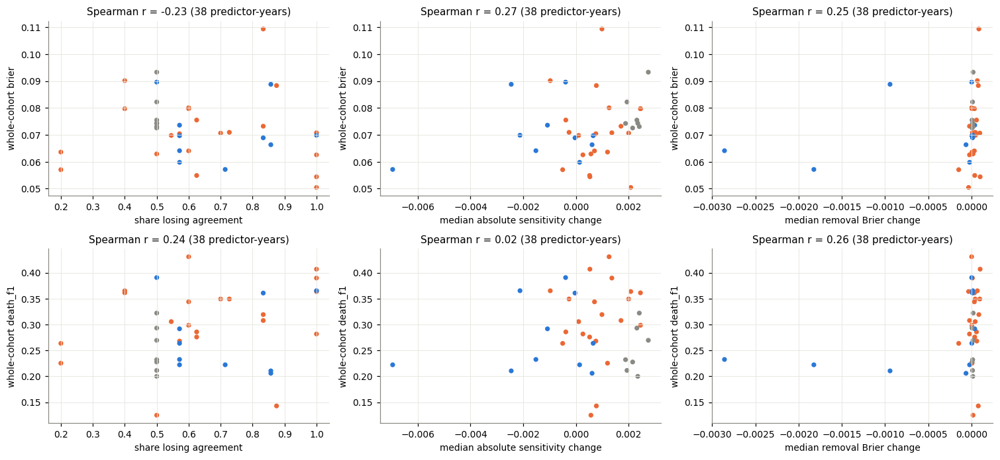

In [33]:
links = []
reference_values = point[point.year == point.reference].set_index(["concept", "group"])
for (build, reference, year), part in point[group_mask["R"] & outcome_mask].groupby(["build", "reference", "year"]):
    if year == reference:
        continue
    base = reference_values.loc[[(c, "R") for c in part.concept]]
    links.append({"build": build, "reference": reference, "year": year, "families": len(part),
                  "share losing agreement": float(np.mean(part.agreement.to_numpy() < base.agreement.to_numpy())),
                  "median absolute sensitivity change": float(np.nanmedian(part.absolute_sensitivity.to_numpy() - base.absolute_sensitivity.to_numpy())),
                  "median removal Brier change": float(np.nanmedian(part.removal_brier_change))})
links = pd.DataFrame(links).merge(my_cohort, on=["build", "reference", "year"])
fig, axes = plots.grid(6, columns=3, width=4.6)
for ax, (x, y) in zip(axes, [(x, y) for y in ("brier", "death_f1") for x in
                             ("share losing agreement", "median absolute sensitivity change", "median removal Brier change")]):
    ax.scatter(links[x], links[y], s=14, color=[plots.VARIANT_COLOURS.get(b, plots.GREY) for b in links.build])
    r = associations.spearman(links[x].to_numpy()[None], links[y].to_numpy()[None])[0]
    ax.set(xlabel=x, ylabel=f"whole-cohort {y}", title=f"Spearman r = {r:.2f} ({len(links)} predictor-years)")
fig.tight_layout()
plt.show()

## Step 6b — Who the patients are: feature profiles inside the groups
Showcase: the factor-49 family and the three last_3 families with the largest agreement decline from the
reference year to 2014. Full tables for every concept are saved in `stats/concept_agreement_study/features/`.

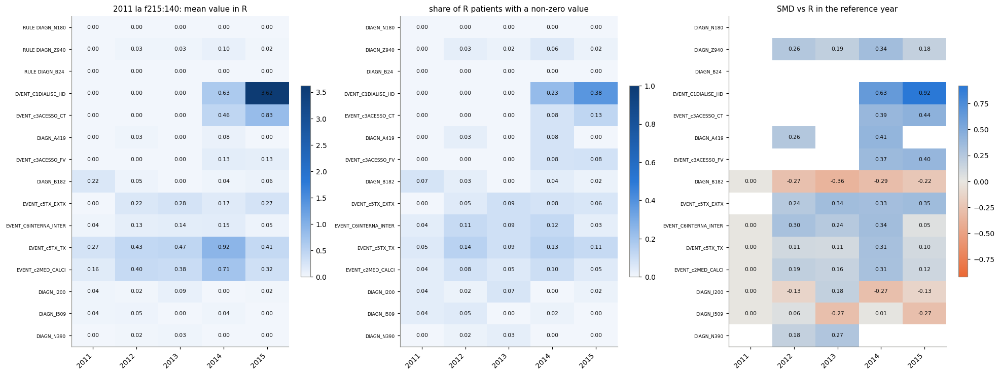

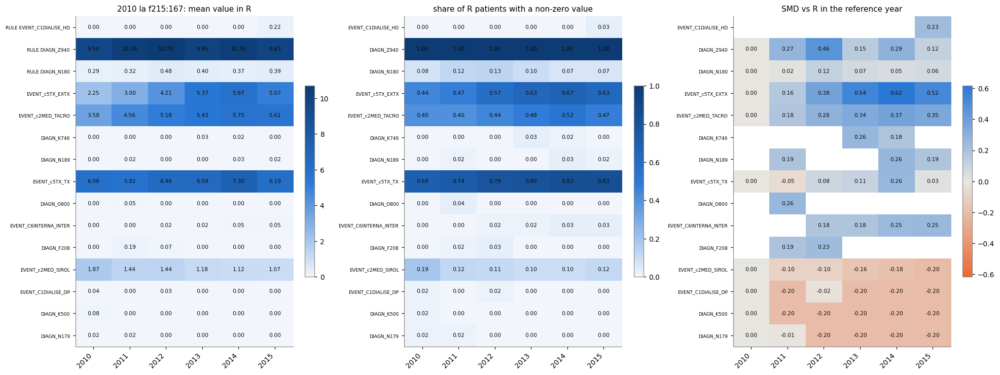

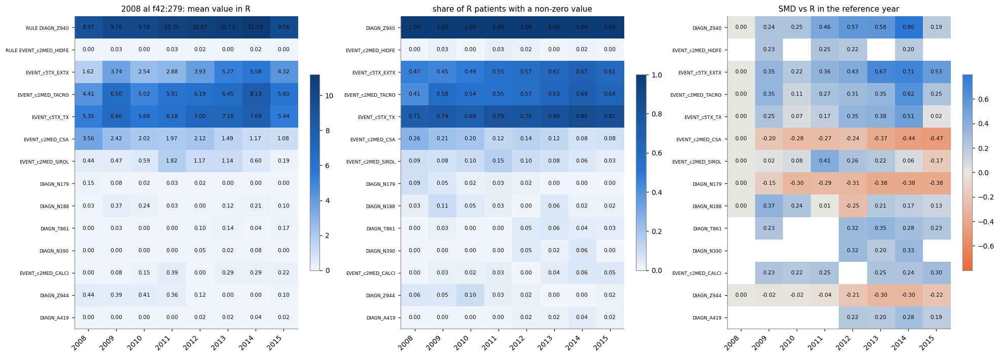

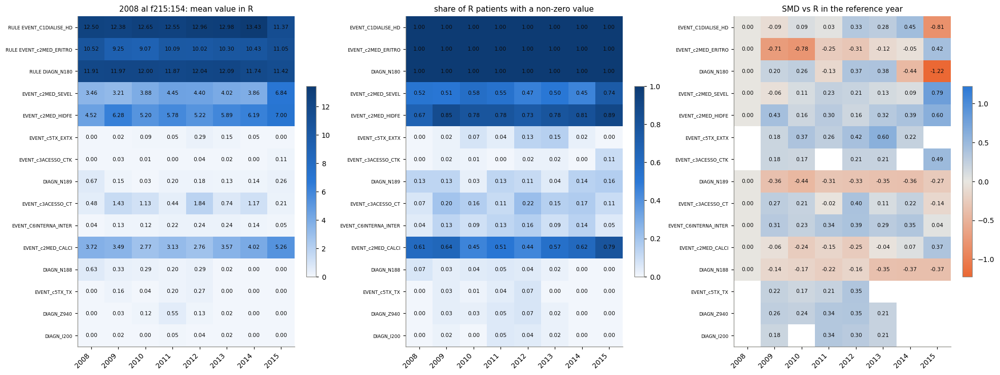

In [34]:
declines = last_pair[last_pair.variants.str.contains("last_3")].sort_values("total")
showcase = [showcase[0]] + [next(r for r in cav_records if r["concept"] == c)
                            for c in declines.concept if c != showcase[0]["concept"]][:3]
for record in showcase:
    profile = features.load_features(record)
    names = profile["feature_names"]
    g = measures.GROUPS.index("R")
    years = [y for y in measures.YEARS if y >= record["reference"]]
    columns = [measures.YEARS.index(y) for y in years]
    rule = list(profile["rule_columns"])
    shift = np.nanmax(np.abs(profile["smd_vs_reference"][g][columns]), axis=0)
    top = [j for j in np.argsort(-np.nan_to_num(shift)) if j not in rule][:12]
    chosen = rule + top
    fig, axes = plt.subplots(1, 3, figsize=(18, 0.32 * len(chosen) + 2))
    plots.heatmap(axes[0], profile["mean"][g][columns][:, chosen].T, [("RULE " if j in rule else "") + names[j] for j in chosen],
                  years, title=f"{label[record['concept']]}: mean value in R")
    plots.heatmap(axes[1], profile["nonzero_share"][g][columns][:, chosen].T, [names[j] for j in chosen], years,
                  title="share of R patients with a non-zero value", limit=1)
    plots.heatmap(axes[2], profile["smd_vs_reference"][g][columns][:, chosen].T, [names[j] for j in chosen], years,
                  diverging=True, title="SMD vs R in the reference year")
    for ax in axes:
        ax.tick_params(axis="y", labelsize=6)
    fig.tight_layout()
    plt.show()

**Why rule patients stop activating the factor.** R+A− versus R+A+ in the same year: SMD per feature with
joint-bootstrap intervals (the year up to 2014 where the smaller of the two groups is largest; top 15 by |SMD| shown).

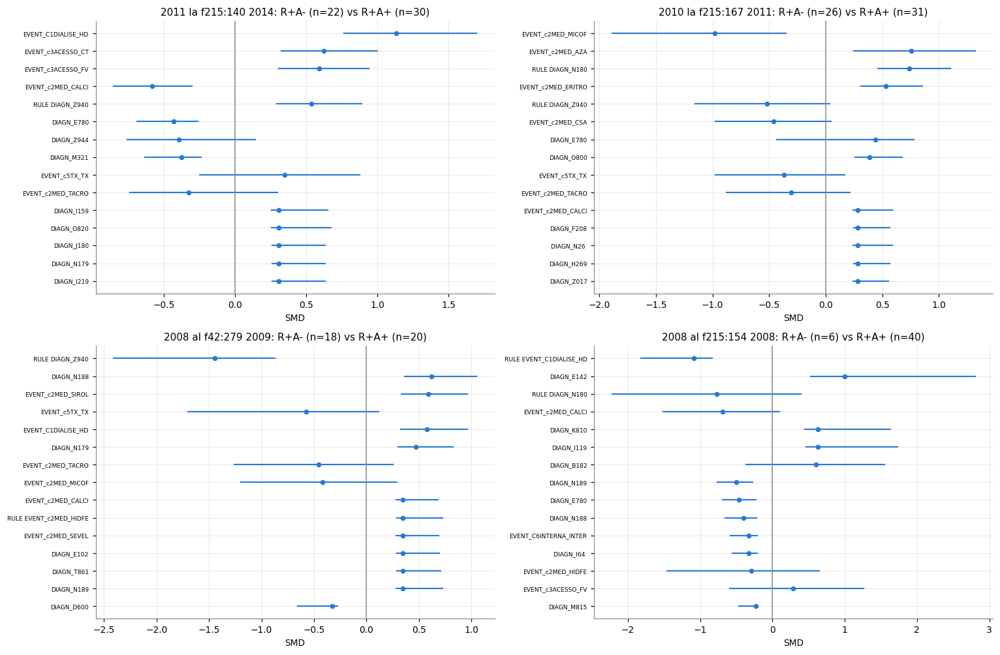

In [35]:
fig, axes = plots.grid(len(showcase), columns=2, width=7, height=4.6)
for ax, record in zip(axes, showcase):
    profile = features.load_features(record)
    lost, kept = measures.GROUPS.index("R+A-"), measures.GROUPS.index("R+A+")
    usable = [y for y, year in enumerate(measures.YEARS) if year <= paths.LAST_OUTCOME_YEAR
              and profile["count"][lost, y] > 0 and profile["count"][kept, y] > 0]
    if not usable:
        ax.set_visible(False)
        continue
    y = max(usable, key=lambda k: min(profile["count"][lost, k], profile["count"][kept, k]))   # best-supported year
    value = profile["smd_stopped_vs_kept"][y]
    order = np.argsort(-np.nan_to_num(np.abs(value)))[:15]
    rule = set(profile["rule_columns"])
    plots.forest(ax, [("RULE " if j in rule else "") + profile["feature_names"][j] for j in order], value[order],
                 profile["smd_stopped_vs_kept_low"][y][order], profile["smd_stopped_vs_kept_high"][y][order],
                 title=f"{label[record['concept']]} {measures.YEARS[y]}: R+A- (n={profile['count'][lost, y]:.0f}) "
                       f"vs R+A+ (n={profile['count'][kept, y]:.0f})", xlabel="SMD")
    ax.tick_params(axis="y", labelsize=6)
fig.tight_layout()
plt.show()

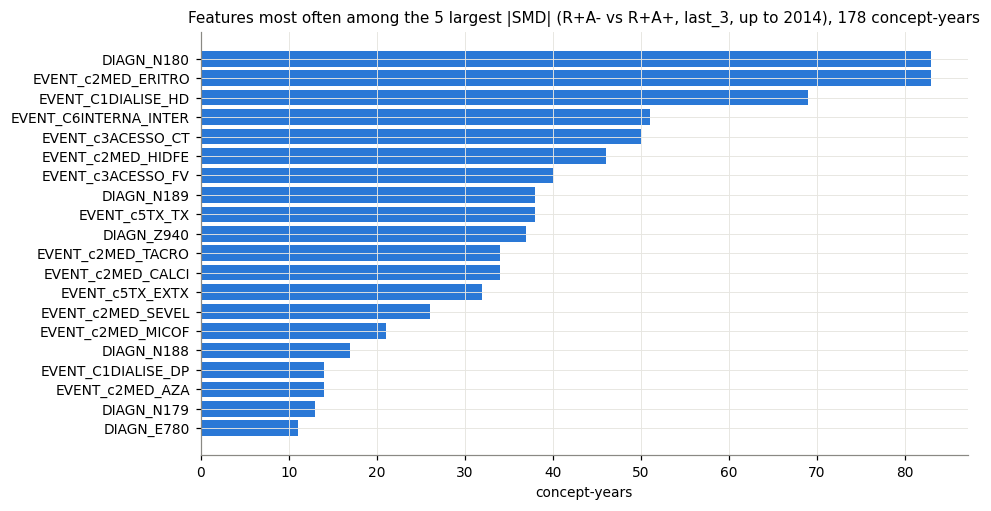

,median_abs_smd,times_in_top_5
feature,,
DIAGN_N180,0.7534,83
EVENT_c2MED_ERITRO,0.7142,83
EVENT_C1DIALISE_HD,0.8741,69
EVENT_C6INTERNA_INTER,0.5562,51
EVENT_c3ACESSO_CT,0.5906,50
EVENT_c2MED_HIDFE,0.5547,46
EVENT_c3ACESSO_FV,0.5561,40
DIAGN_N189,0.5153,38
EVENT_c5TX_TX,0.4596,38


In [36]:
recurrence = []
for record in last3_records:                              # same concept-years as the R+A- cells of Step 6
    profile = features.load_features(record)
    lost, kept = measures.GROUPS.index("R+A-"), measures.GROUPS.index("R+A+")
    for y, year in enumerate(measures.YEARS):
        if profile["count"][lost, y] > 0 and profile["count"][kept, y] > 0 and record["reference"] <= year <= paths.LAST_OUTCOME_YEAR:
            recurrence.append(pd.DataFrame({"concept": record["concept"], "year": year,
                                            "feature": profile["feature_names"],
                                            "abs_smd": np.abs(profile["smd_stopped_vs_kept"][y])}))
recurrence = pd.concat(recurrence)
recurrence["rank"] = recurrence.groupby(["concept", "year"]).abs_smd.rank(ascending=False)
summary = recurrence.groupby("feature").agg(median_abs_smd=("abs_smd", "median"),
                                            times_in_top_5=("rank", lambda r: int((r <= 5).sum())))
summary = summary.sort_values("times_in_top_5", ascending=False).head(20)
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(summary.index[::-1], summary.times_in_top_5[::-1], color=plots.BLUE)
ax.set(title=f"Features most often among the 5 largest |SMD| (R+A- vs R+A+, last_3, up to 2014), "
             f"{recurrence[['concept', 'year']].drop_duplicates().shape[0]} concept-years", xlabel="concept-years")
plt.show()
display(summary)

**Composition.** Patients of a group with no evaluation row in the previous year ("entering": new to the cohort or
back after a gap) versus patients of the same group who had one ("returning", in whatever group they were then):
mean |SMD| over all features, per concept-year; and the factor-49 family in detail.

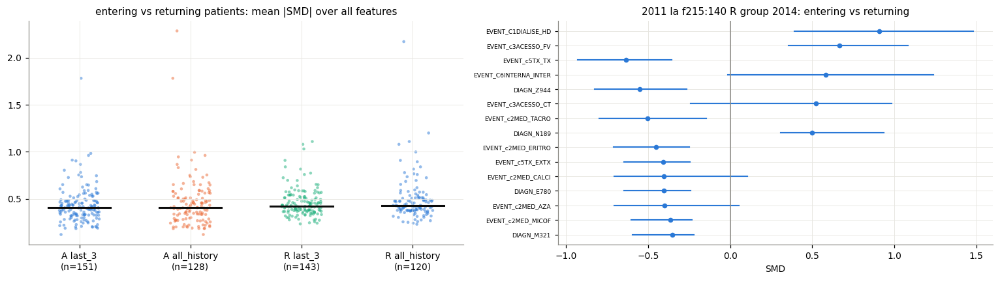

In [37]:
flow = []
for record in cav_records:
    profile = features.load_features(record)
    for gi, group in enumerate(("A", "R")):
        for y, year in enumerate(measures.YEARS):
            if year > record["reference"] and profile["flow_count"][gi, y].min() > 1:
                flow.append({"concept": record["concept"], "variants": ",".join(record["variants"]), "group": group,
                             "year": year, "mean_abs_smd": np.nanmean(np.abs(profile["smd_entering_vs_returning"][gi, y])),
                             "rule_features_mean_abs_smd": np.nanmean(np.abs(profile["smd_entering_vs_returning"][gi, y][profile["rule_columns"]]))
                             if len(profile["rule_columns"]) else np.nan})
flow = pd.DataFrame(flow)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plots.strip(axes[0], {f"{g} {v}": flow[(flow.group == g) & flow.variants.str.contains(v)].mean_abs_smd
                      for g in ("A", "R") for v in paths.VARIANTS},
            title="entering vs returning patients: mean |SMD| over all features", zero=False)
profile = features.load_features(showcase[0])
r_index = 1
y = measures.YEARS.index(2014)
value = profile["smd_entering_vs_returning"][r_index, y]
order = np.argsort(-np.nan_to_num(np.abs(value)))[:15]
plots.forest(axes[1], [profile["feature_names"][j] for j in order], value[order],
             profile["smd_entering_vs_returning_low"][r_index, y][order],
             profile["smd_entering_vs_returning_high"][r_index, y][order],
             title=f"{label[showcase[0]['concept']]} R group 2014: entering vs returning", xlabel="SMD")
axes[1].tick_params(axis="y", labelsize=6)
fig.tight_layout()
plt.show()

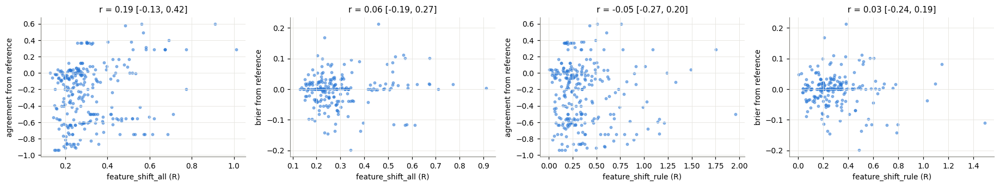

In [38]:
since_reference = point.year - point.reference
first_index = np.arange(len(point)) - point.groupby(["concept", "group"]).cumcount().to_numpy()  # reference-year row
cube["agreement_from_reference"] = cube["agreement"] - cube["agreement"][:, first_index]
cube["brier_from_reference"] = cube["brier"] - cube["brier"][:, first_index]
point["agreement_from_reference"] = cube["agreement_from_reference"][0]
point["brier_from_reference"] = cube["brier_from_reference"][0]
fig, axes = plots.grid(4, columns=4, width=4.2)
later = (since_reference > 0).to_numpy()
for ax, (shift, other) in zip(axes, [(s, o) for s in ("feature_shift_all", "feature_shift_rule")
                                     for o in ("agreement_from_reference", "brier_from_reference")]):
    mask = variant_mask["last_3"] & group_mask["R"] & later & (outcome_mask if other.startswith("brier") else True)
    sub_point, sub_cube = associations.select(point, cube, mask)
    r = associations.summarize(associations.correlation(sub_cube[shift], sub_cube[other], sub_point.concept.to_numpy()))
    ax.scatter(sub_point[shift], sub_point[other], s=8, alpha=0.5, color=plots.BLUE)
    ax.set(xlabel=f"{shift} (R)", ylabel=other.replace("_", " "), title=f"r = {r['r']:.2f} [{r['low']:.2f}, {r['high']:.2f}]")
fig.tight_layout()
plt.show()

## Step 7 — Lead/lag: concept change at *t* versus performance at *t+1, t+2, t+3*
Features fixed in advance (level and last-year change). Targets: Brier and Death-F1 at *t+h* and their change
from *t*; outcomes ≤ 2014. Adjustments: none, current value of the target, and current value + concept +
predictor-year + mortality + log size; the three use the same rows (complete on all of these). Saved measures
(fresh-rule gap, yearly alignment) have point values only.

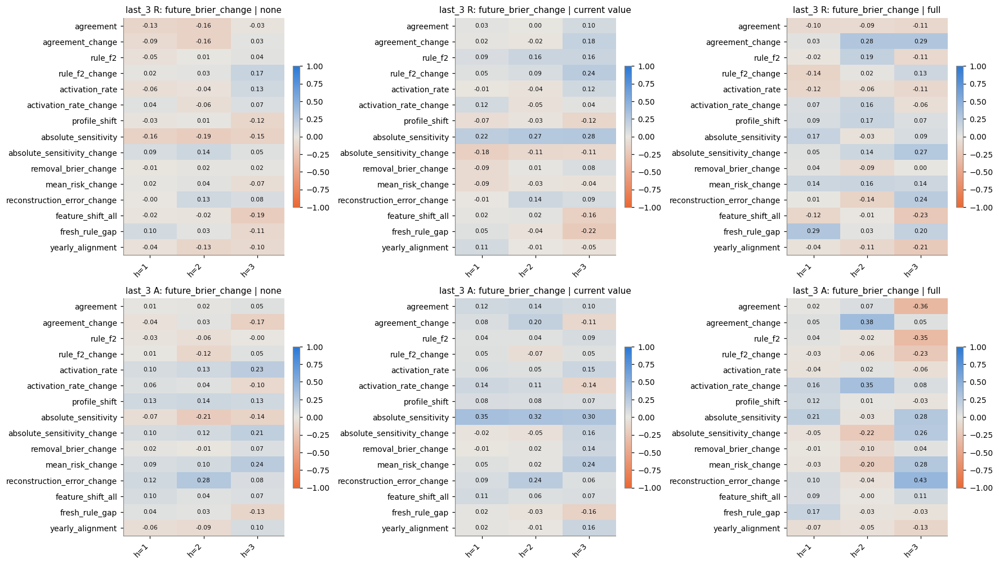

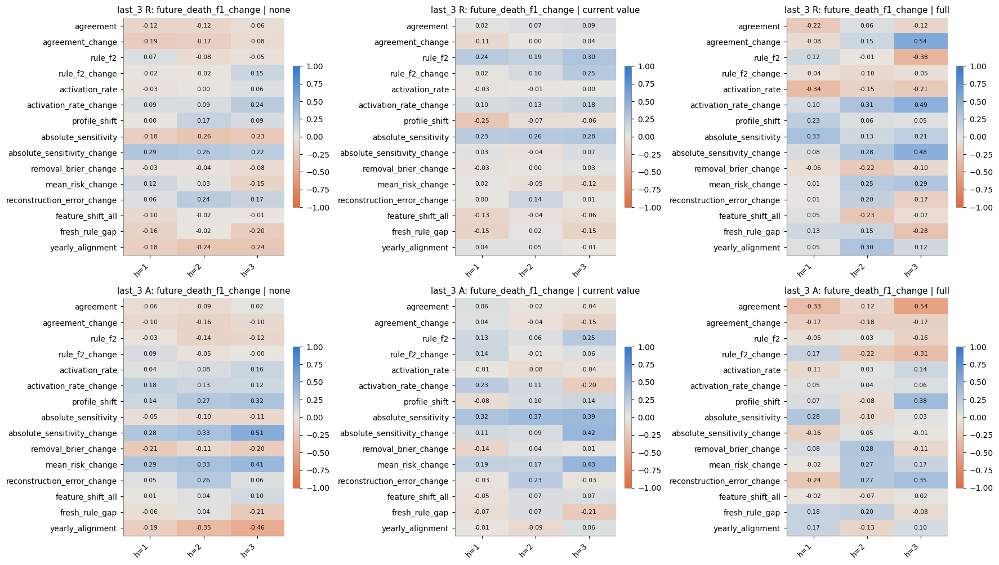

In [39]:
LEAD_FEATURES = ["agreement", "agreement_change", "rule_f2", "rule_f2_change", "activation_rate",
                 "activation_rate_change", "profile_shift", "absolute_sensitivity", "absolute_sensitivity_change",
                 "removal_brier_change", "mean_risk_change", "reconstruction_error_change", "feature_shift_all",
                 "fresh_rule_gap", "yearly_alignment"]
horizon_panels = {h: associations.horizon_panel(point, cube, h, ["brier", "death_f1", "agreement", "absolute_sensitivity",
                                                                 "activation_rate", "tcav"]) for h in (1, 2, 3)}
keys = {h: set(zip(p.concept, p.group, p.year)) for h, (p, _) in horizon_panels.items()}
common_rows = keys[1] & keys[2] & keys[3]
cells = []
for h, (hp, hc) in horizon_panels.items():
    hp_variant = {v: associations.in_variant(hp, v) for v in paths.VARIANTS}
    common = np.array([(c, g, y) in common_rows for c, g, y in zip(hp.concept, hp.group, hp.year)])
    for variant in paths.VARIANTS:
        for group in ("A", "R"):
            for sample, sample_mask in (("available", np.ones(len(hp), bool)), ("same starting rows", common)):
                mask = hp_variant[variant] & (hp.group == group).to_numpy() & sample_mask
                for feature in LEAD_FEATURES:
                    for target in ("brier", "death_f1"):
                        for kind in ("", "_change"):
                            for adjustment, controls in (("none", []), ("current value", [target]),
                                                         ("full", ["concept", "predictor_year", target, "mortality", "log_n"])):
                                cells.append({"horizon": h, "variant": variant, "group": group, "sample": sample,
                                              "feature": feature, "target": f"future_{target}{kind}",
                                              "adjustment_name": adjustment, "controls": controls, "mask": mask})
lead = pd.concat([associations.grid(hp, hc, [c for c in cells if c["horizon"] == h]) for h, (hp, hc) in horizon_panels.items()],
                 ignore_index=True)
lead.to_csv(paths.OUTPUT / "lead_lag.csv", index=False)

for target in ("future_brier_change", "future_death_f1_change"):
    fig, axes = plots.grid(6, columns=3, width=5.4, height=4.6)
    for ax, (group, adjustment) in zip(axes, [(g, a) for g in ("R", "A") for a in ("none", "current value", "full")]):
        part = lead[(lead.variant == "last_3") & (lead.group == group) & (lead.target == target)
                    & (lead.adjustment_name == adjustment) & (lead["sample"] == "available")]
        matrix = part.pivot(index="feature", columns="horizon", values="r").reindex(LEAD_FEATURES)
        plots.heatmap(ax, matrix.to_numpy(), matrix.index, [f"h={h}" for h in matrix.columns], diverging=True, limit=1,
                      title=f"last_3 {group}: {target} | {adjustment}")
    fig.tight_layout()
    plt.show()

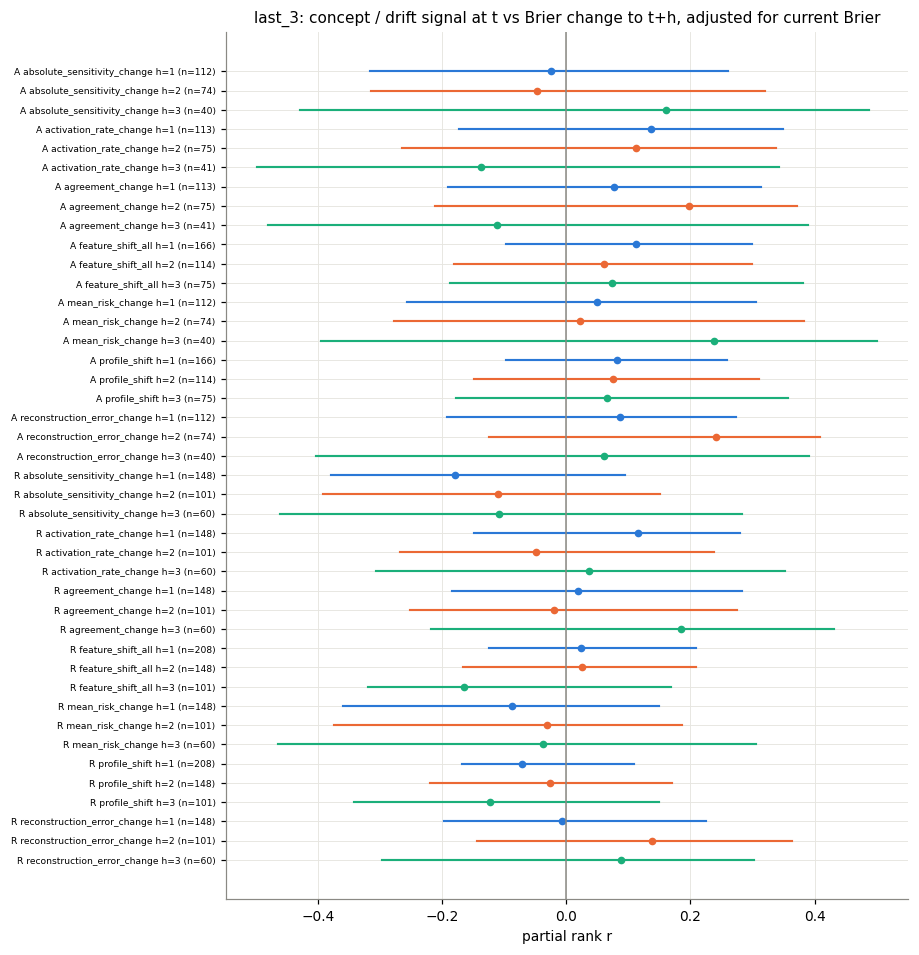

In [40]:
part = lead[(lead.variant == "last_3") & (lead.target == "future_brier_change") & (lead.adjustment_name == "current value")
            & (lead["sample"] == "available") & lead.feature.isin(["agreement_change", "absolute_sensitivity_change",
                                                                   "activation_rate_change", "profile_shift", "mean_risk_change",
                                                                   "reconstruction_error_change", "feature_shift_all"])]
part = part.sort_values(["group", "feature", "horizon"])
fig, ax = plt.subplots(figsize=(8, 0.22 * len(part) + 1))
plots.forest(ax, [f"{r.group} {r.feature} h={r.horizon} (n={r.rows})" for r in part.itertuples()],
             part.r.to_numpy(), part.low.to_numpy(), part.high.to_numpy(),
             colours=[plots.SERIES[r.horizon - 1] for r in part.itertuples()],
             title="last_3: concept / drift signal at t vs Brier change to t+h, adjusted for current Brier", xlabel="partial rank r")
ax.tick_params(axis="y", labelsize=6)
plt.show()

**Reverse direction.** Does performance move first? Brier change at *t* versus concept change from *t* to *t+h*.

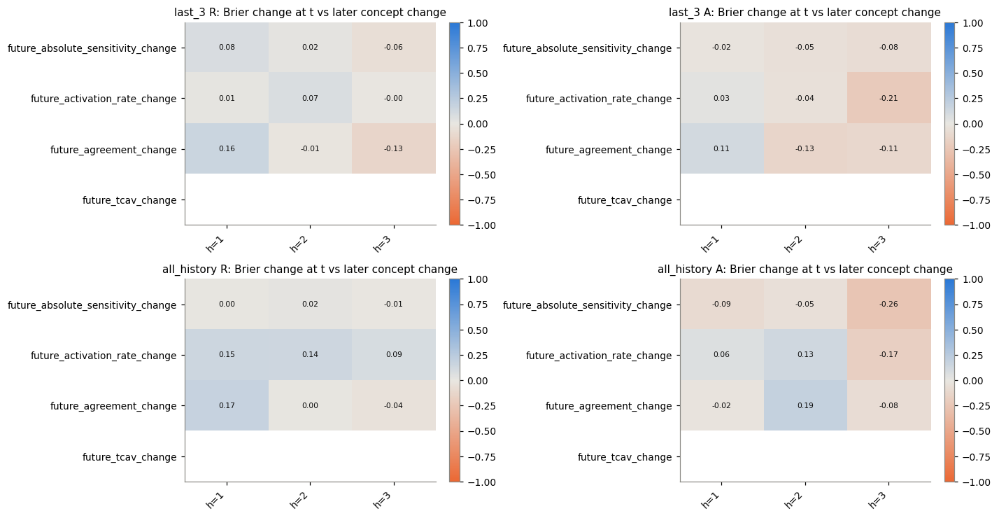

In [41]:
cells = []
for h, (hp, hc) in horizon_panels.items():
    for variant in paths.VARIANTS:
        for group in ("A", "R"):
            mask = associations.in_variant(hp, variant) & (hp.group == group).to_numpy()
            for target in ("future_agreement_change", "future_absolute_sensitivity_change", "future_activation_rate_change",
                           "future_tcav_change"):
                for feature in ("brier_change", "death_f1_change"):
                    cells.append({"horizon": h, "variant": variant, "group": group, "feature": feature,
                                  "target": target, "controls": [], "mask": mask})
reverse = pd.concat([associations.grid(hp, hc, [c for c in cells if c["horizon"] == h]) for h, (hp, hc) in horizon_panels.items()],
                    ignore_index=True)
reverse.to_csv(paths.OUTPUT / "reverse_direction.csv", index=False)
fig, axes = plots.grid(4, columns=2, width=6.5, height=3.4)
for ax, (variant, group) in zip(axes, [(v, g) for v in paths.VARIANTS for g in ("R", "A")]):
    part = reverse[(reverse.variant == variant) & (reverse.group == group) & (reverse.feature == "brier_change")]
    matrix = part.pivot(index="target", columns="horizon", values="r")
    plots.heatmap(ax, matrix.to_numpy(), matrix.index, [f"h={h}" for h in matrix.columns], diverging=True, limit=1,
                  title=f"{variant} {group}: Brier change at t vs later concept change")
fig.tight_layout()
plt.show()

**Chronological forecasts** of the Brier change to *t+h* (h = 1, 2): ridge on history only versus history plus
one block; trained only on rows whose outcome was known at the forecast origin. Negative = lower error than
history only. Only target years with enough matured training rows can be fitted (table below).

Training rows per target year (forecasts need at least 20; earlier years have too few matured outcomes):


target_year                                       2011  2012  2013  2014
variant     group horizon target                                        
all_history A     1       future_brier_change        7    21    42    67
                          future_death_f1_change     6    16    30    50
                  2       future_brier_change        0     2     7    20
                          future_death_f1_change     0     2     6    14
            R     1       future_brier_change       14    34    62    95
                          future_death_f1_change     4    13    28    48
                  2       future_brier_change        0     4    14    34
                          future_death_f1_change     0     0     5    14
last_3      A     1       future_brier_change        7    21    41    74
                          future_death_f1_change     6    16    31    59
                  2       future_brier_change        0     2     7    20
                          future_death_f1_change     0     2     6    14
            R     1       future_brier_change       14    34    61   102
                          future_death_f1_change     4    13    28    55
                  2       future_brier_change        0     4    14    34
                          future_death_f1_change     0     0     5    14

% change in forecast error versus history only (negative = block helps), alpha 10:


target_year                                                           2012  2013  2014
variant     group horizon target                 model                                
all_history A     1       future_brier_change    + agreement           4.8  -9.2 -12.8
                                                 + drift comparators  -8.8   8.4  15.6
                                                 + influence          22.2 -19.6   0.1
                                                 + removal           -20.9  10.6  -9.5
                                                 + representation     11.1   6.1  -1.1
                          future_death_f1_change + agreement           NaN  18.3   0.8
                                                 + drift comparators   NaN  13.1   0.9
                                                 + influence           NaN   5.2   0.4
                                                 + removal             NaN  -0.4 -14.1
                                                 + representation      NaN   9.1   0.3
                  2       future_brier_change    + agreement           NaN   NaN   2.1
                                                 + drift comparators   NaN   NaN -22.5
                                                 + influence           NaN   NaN -19.4
                                                 + removal             NaN   NaN   2.2
                                                 + representation      NaN   NaN  17.1
            R     1       future_brier_change    + agreement          19.1   1.9   0.5
                                                 + drift comparators   9.8   3.7   6.3
                                                 + influence           7.6 -10.6  -6.7
                                                 + removal           -11.0   6.9   0.8
                                                 + representation     21.0   0.3  -2.7
                          future_death_f1_change + agreement           NaN -10.9   5.7
                                                 + drift comparators   NaN  -5.6   7.7
                                                 + influence           NaN -14.4  -2.2
                                                 + removal             NaN   0.5   6.9
                                                 + representation      NaN   2.6  -3.0
                  2       future_brier_change    + agreement           NaN   NaN   0.9
                                                 + drift comparators   NaN   NaN  13.4
                                                 + influence           NaN   NaN   1.5
                                                 + removal             NaN   NaN  -5.2
                                                 + representation      NaN   NaN   5.8
last_3      A     1       future_brier_change    + agreement           9.4  -0.5   6.9
                                                 + drift comparators  -3.9  -8.5   6.5
                                                 + influence          28.5 -14.6  -0.1
                                                 + removal           -21.1  56.5  -0.2
                                                 + representation     11.3   9.9   0.4
                          future_death_f1_change + agreement           NaN  13.8  -1.6
                                                 + drift comparators   NaN  -9.8  -6.8
                                                 + influence           NaN  -6.4  -4.2
                                                 + removal             NaN  65.4  -3.3
                                                 + representation      NaN   7.1   6.1
                  2       future_brier_change    + agreement           NaN   NaN   1.3
                                                 + drift comparators   NaN   NaN  -2.1
                                                 + influence           NaN   NaN  -2.5
                                                 + removal             NaN   NaN   0.

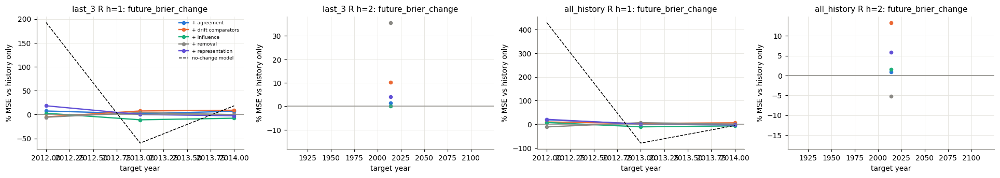

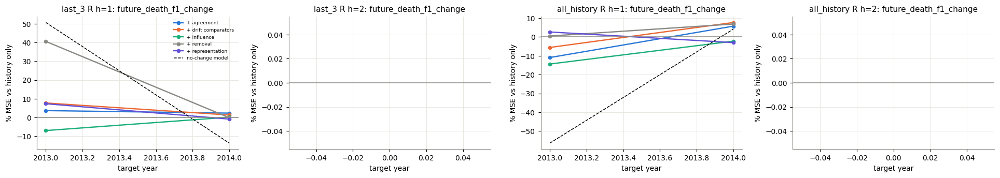

In [42]:
BLOCKS = {"+ agreement": ["agreement", "agreement_change"], "+ representation": ["activation_rate", "profile_shift"],
          "+ influence": ["absolute_sensitivity", "absolute_sensitivity_change"], "+ removal": ["removal_brier_change"],
          "+ drift comparators": ["mean_risk_change", "reconstruction_error_change", "feature_shift_all"]}
scores = []
for h in (1, 2):
    hp, _ = horizon_panels[h]
    for variant in paths.VARIANTS:
        for group in ("A", "R"):
            part = hp[associations.in_variant(hp, variant) & (hp.group == group).to_numpy()]
            for target in ("future_brier_change", "future_death_f1_change"):
                base = target.replace("future_", "").replace("_change", "")
                result = forecasts.chronological_forecasts(part, target, [base, f"{base}_change"], BLOCKS, h)
                result["variant"], result["group"] = variant, group
                scores.append(result)
scores = pd.concat(scores, ignore_index=True)
scores.to_csv(paths.OUTPUT / "forecasts.csv", index=False)
compared = forecasts.compare_to_history(scores)
history_rows = scores[scores.model == "history only"]
coverage = (history_rows.drop_duplicates(["variant", "group", "horizon", "target", "target_year"])
            .pivot_table(index=["variant", "group", "horizon", "target"], columns="target_year",
                         values="train_rows", aggfunc="first"))
print(f"Training rows per target year (forecasts need at least {paths.MIN_TRAINING_ROWS}; earlier years have too few matured outcomes):")
display(coverage)
summary = compared[(compared.model != "history only")].pivot_table(
    index=["variant", "group", "horizon", "target", "model"], columns="target_year",
    values="mse_change_vs_history_percent").round(1)
print("% change in forecast error versus history only (negative = block helps), alpha 10:")
display(summary)
for target in ("future_brier_change", "future_death_f1_change"):
    fig, axes = plots.grid(4, columns=4, width=4.4)
    for ax, (variant, h) in zip(axes, [(v, h) for v in paths.VARIANTS for h in (1, 2)]):
        part = compared[(compared.variant == variant) & (compared.horizon == h) & (compared.group == "R")
                        & (compared.target == target) & (compared.model != "history only")]
        for k, (model, rows) in enumerate(part.groupby("model")):
            ax.plot(rows.target_year, rows.mse_change_vs_history_percent, marker="o",
                    color=(plots.SERIES + (plots.GREY, "#6250d6"))[k], label=model)
        no_change = compared[(compared.variant == variant) & (compared.horizon == h) & (compared.group == "R")
                             & (compared.target == target) & (compared.model == "history only")]
        ax.plot(no_change.target_year, 100 * (no_change.mse_no_change / no_change.mse - 1), "k--", lw=1, label="no-change model")
        ax.axhline(0, color=plots.GREY, lw=1)
        ax.set(title=f"{variant} R h={h}: {target}", xlabel="target year", ylabel="% MSE vs history only")
    axes[0].legend(fontsize=6)
    fig.tight_layout()
    plt.show()

## Step 8 — Year-input experiment
Later evaluation patients re-scored with their features unchanged and the year input set to the reference year.

builds scored: 11 of 11


,build,reference,year,n,brier_difference,brier_low,brier_high,mean_risk_true,mean_risk_swapped,mortality
0,all_history,2008,2009,314,-6.0173e-05,-9.8277e-04,8.7526e-04,0.0628,0.0554,0.0732
1,all_history,2008,2010,333,-1.4221e-04,-1.0930e-03,8.5601e-04,0.0665,0.0572,0.0721
2,all_history,2008,2011,325,1.0197e-03,-2.5636e-04,2.4505e-03,0.0743,0.0612,0.1262
3,all_history,2008,2012,310,-6.9705e-04,-1.8300e-03,4.2705e-04,0.0743,0.0589,0.0903
4,all_history,2008,2013,314,1.2109e-04,-1.5769e-03,1.7490e-03,0.0772,0.0588,0.0860
5,all_history,2008,2014,309,7.5928e-05,-1.2165e-03,1.3057e-03,0.0785,0.0601,0.0615
6,all_history,2009,2010,325,2.0288e-05,-3.8147e-04,4.6712e-04,0.0748,0.0684,0.0800
7,all_history,2009,2011,305,3.0841e-04,-4.0317e-04,1.0780e-03,0.0719,0.0615,0.1049
8,all_history,2009,2012,329,6.5387e-04,-2.7214e-04,1.5833e-03,0.0792,0.0652,0.0973
9,all_history,2009,2013,329,1.1365e-03,-2.4943e-04,2.6910e-03,0.0815,0.0648,0.0942


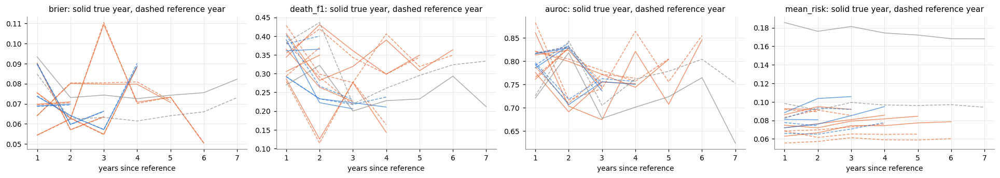

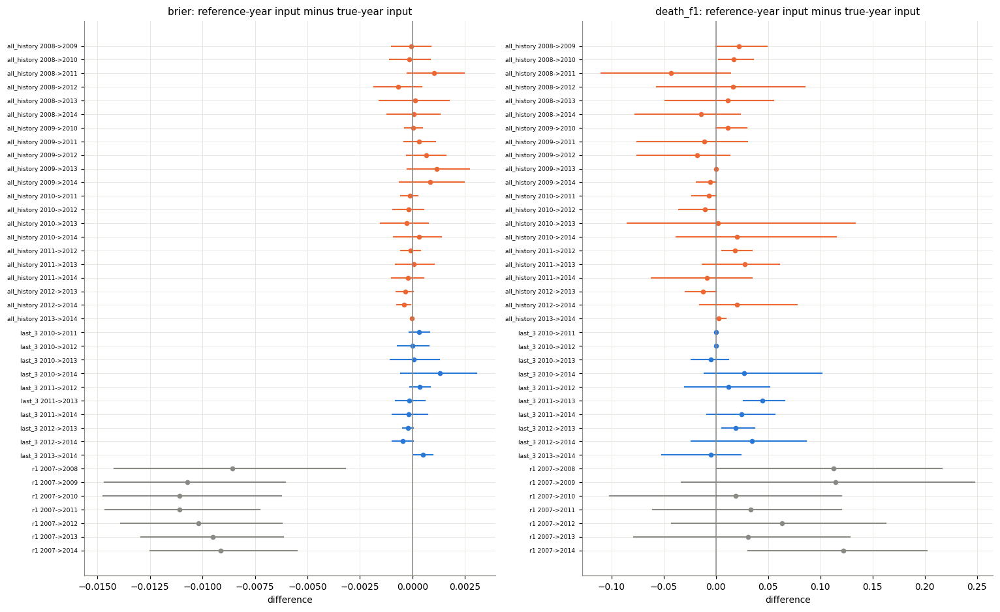

In [43]:
year_cohort, year_concepts = cohort.year_input_table(index)
year_cohort.to_csv(paths.OUTPUT / "year_input_cohort.csv", index=False)
year_concepts.to_csv(paths.OUTPUT / "year_input_concepts.csv", index=False)
print(f"builds scored: {year_cohort[['build', 'reference']].drop_duplicates().shape[0]} of {len(index['builds'])}")
scored = year_cohort.dropna(subset=["brier_true"])
with pd.option_context("display.max_rows", 80):
    display(scored[["build", "reference", "year", "n", "brier_difference", "brier_low", "brier_high",
                    "mean_risk_true", "mean_risk_swapped"]]
            .merge(my_cohort[["build", "reference", "year", "mortality"]], on=["build", "reference", "year"]))
fig, axes = plots.grid(4, columns=4, width=4.4)
for ax, metric in zip(axes, ("brier", "death_f1", "auroc", "mean_risk")):
    for (build, reference), part in scored.groupby(["build", "reference"]):
        colour = plots.VARIANT_COLOURS.get(build, plots.GREY)
        ax.plot(part.years_since_reference, part[f"{metric}_true"], color=colour, lw=1, alpha=0.7)
        ax.plot(part.years_since_reference, part[f"{metric}_swapped"], color=colour, lw=1, ls="--", alpha=0.7)
    ax.set(title=f"{metric}: solid true year, dashed reference year", xlabel="years since reference")
fig.tight_layout()
plt.show()
part = scored.sort_values(["build", "reference", "year"])
fig, axes = plt.subplots(1, 2, figsize=(14, 0.2 * len(part) + 1))
for ax, metric in zip(axes, ("brier", "death_f1")):
    plots.forest(ax, [f"{b} {r}->{y}" for b, r, y in part[["build", "reference", "year"]].itertuples(index=False)],
                 part[f"{metric}_difference"].to_numpy(), part[f"{metric}_low"].to_numpy(), part[f"{metric}_high"].to_numpy(),
                 colours=[plots.VARIANT_COLOURS.get(b, plots.GREY) for b in part.build],
                 title=f"{metric}: reference-year input minus true-year input", xlabel="difference")
    ax.tick_params(axis="y", labelsize=6)
fig.tight_layout()
plt.show()

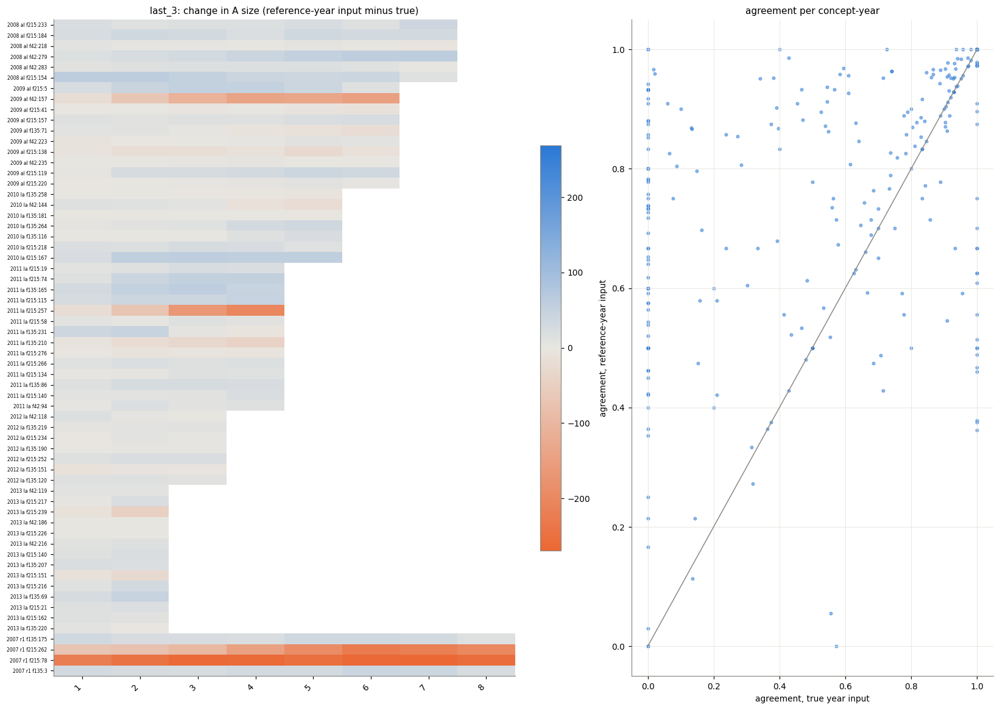

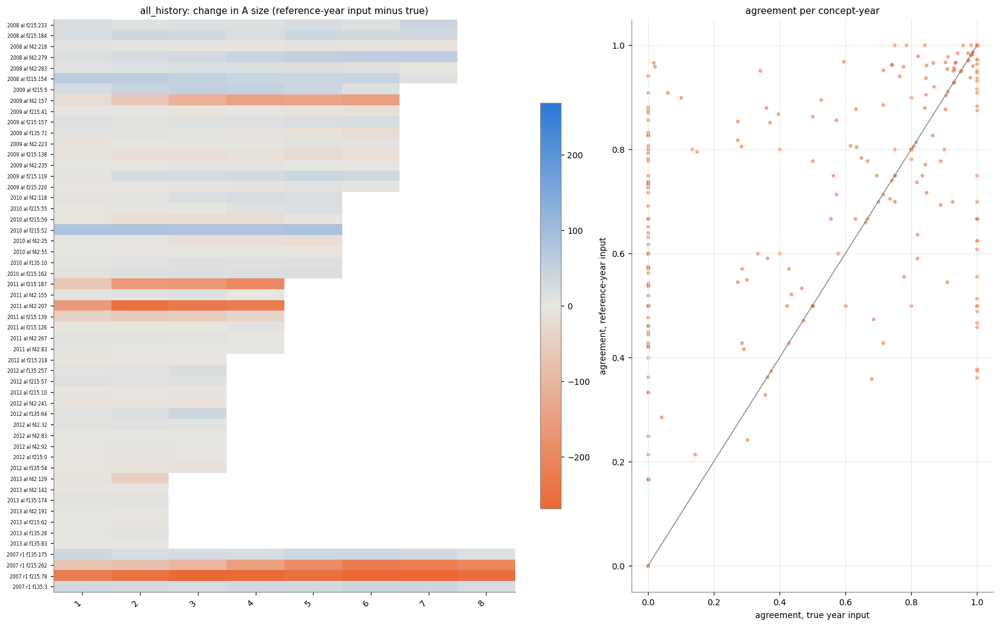

In [44]:
year_concepts["A size change"] = year_concepts.n_A_swapped - year_concepts.n_A_true
for variant in paths.VARIANTS:
    part = year_concepts[year_concepts.variants.str.contains(variant)]
    if part.empty:
        continue
    matrix = part.pivot_table(index="concept", columns="years_since_reference", values="A size change")
    fig, axes = plt.subplots(1, 2, figsize=(15, 0.14 * len(matrix) + 2), gridspec_kw={"width_ratios": [1.4, 1]})
    plots.heatmap(axes[0], matrix.to_numpy(), [label[c] for c in matrix.index], matrix.columns, diverging=True,
                  title=f"{variant}: change in A size (reference-year input minus true)", fmt="{:.0f}")
    axes[0].tick_params(axis="y", labelsize=5)
    axes[1].scatter(part.agreement_true, part.agreement_swapped, s=9, alpha=0.5, color=plots.VARIANT_COLOURS[variant])
    axes[1].plot([0, 1], [0, 1], color=plots.GREY, lw=1)
    axes[1].set(xlabel="agreement, true year input", ylabel="agreement, reference-year input",
                title="agreement per concept-year")
    fig.tight_layout()
    plt.show()

## Step 9 — Statistical validation
**Leonardo's sign count.** (The absolute-sensitivity vs Brier count tracks predicted risk; see Step 10.) Number of concepts whose within-concept correlation (over years) is positive, with
its joint-bootstrap interval and a reference distribution from shuffling years within each concept.

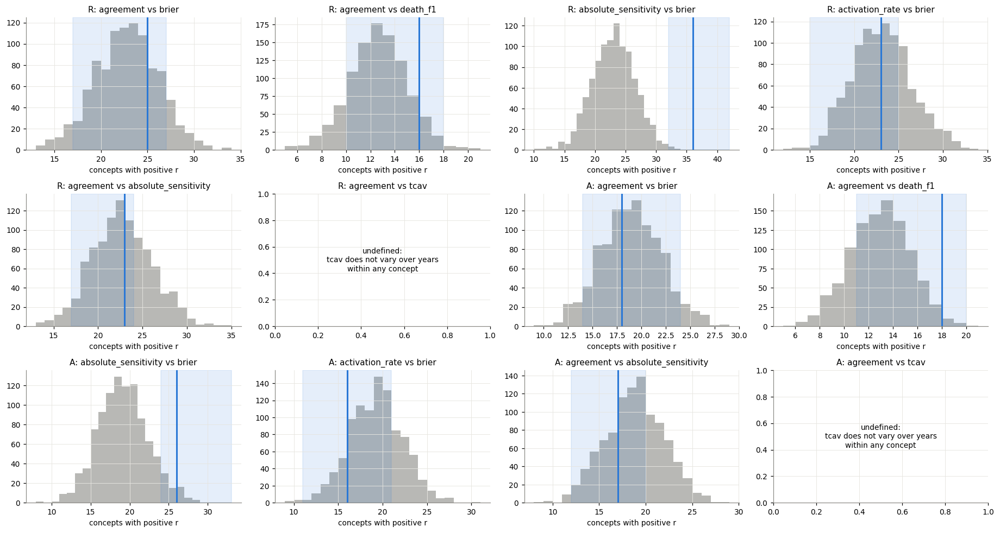

,group,pair,concepts with a defined r,positive,interval,share of shuffles at least as large
0,R,agreement vs brier,46,25.0,"[17, 27]",0.252
1,R,agreement vs death_f1,24,16.0,"[10, 18]",0.077
2,R,absolute_sensitivity vs brier,47,36.0,"[32, 42]",0.000
3,R,activation_rate vs brier,47,23.0,"[15, 25]",0.506
4,R,agreement vs absolute_sensitivity,46,23.0,"[17, 24]",0.448
5,R,agreement vs tcav,0,NaN,undefined,NaN
6,A,agreement vs brier,38,18.0,"[14, 24]",0.615
7,A,agreement vs death_f1,26,18.0,"[11, 20]",0.015
8,A,absolute_sensitivity vs brier,39,26.0,"[24, 33]",0.024
9,A,activation_rate vs brier,39,16.0,"[11, 21]",0.871


In [45]:
sign_rows = []
pairs = [("agreement", "brier"), ("agreement", "death_f1"), ("absolute_sensitivity", "brier"),
         ("activation_rate", "brier"), ("agreement", "absolute_sensitivity"), ("agreement", "tcav")]
fig, axes = plots.grid(len(pairs) * 2, columns=4, width=4.2, height=3)
k = 0
for group in ("R", "A"):
    sub_point, sub_cube = associations.select(point, cube, variant_mask["last_3"] & group_mask[group] & outcome_mask)
    for x, y in pairs:
        table = associations.within_concept(sub_point, sub_cube, x, y)
        defined = np.array([np.isfinite(v[0]) for v in table["values"]])
        ax = axes[k]
        k += 1
        if not defined.any():          # e.g. TCAV: the same value in every year of every concept
            sign_rows.append({"group": group, "pair": f"{x} vs {y}", "concepts with a defined r": 0,
                              "positive": np.nan, "interval": "undefined",
                              "share of shuffles at least as large": np.nan})
            ax.text(0.5, 0.5, f"undefined:\n{y} does not vary over years\nwithin any concept",
                    ha="center", va="center", transform=ax.transAxes)
            ax.set(title=f"{group}: {x} vs {y}")
            continue
        counts = associations.sign_count(table[defined])
        shuffled = associations.shuffled_sign_counts(sub_point, sub_cube, x, y)
        low, high = np.percentile(counts[1:], [2.5, 97.5])
        share = float(np.mean(shuffled >= counts[0]))
        sign_rows.append({"group": group, "pair": f"{x} vs {y}", "concepts with a defined r": int(defined.sum()),
                          "positive": int(counts[0]), "interval": f"[{low:.0f}, {high:.0f}]",
                          "share of shuffles at least as large": share})
        ax.hist(shuffled, bins=range(int(shuffled.min()), int(shuffled.max()) + 2), color=plots.GREY, alpha=0.6)
        ax.axvline(counts[0], color=plots.BLUE, lw=2)
        ax.axvspan(low, high, color=plots.BLUE, alpha=0.12)
        ax.set(title=f"{group}: {x} vs {y}", xlabel="concepts with positive r")
fig.tight_layout()
plt.show()
sign_counts = pd.DataFrame(sign_rows)
display(sign_counts)

**CAV fitting variation.** The same pooled correlations recomputed with each of the 50 fits separately
(point estimates; separate from the patient intervals above).

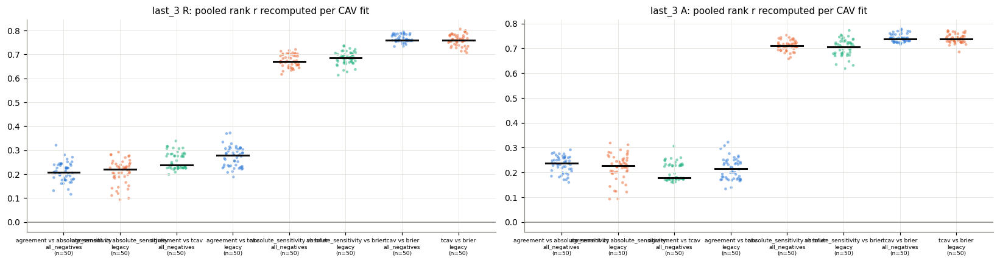

In [46]:
fit_rows = []
for estimator, fits in (("all_negatives", all_negative_fits), ("legacy", legacy_fits)):
    part = fits[fits.variants.str.contains("last_3") & (fits.year <= paths.LAST_OUTCOME_YEAR)]
    wide = part.pivot_table(index=["concept", "group", "year", "draw"], columns="metric", values="value").reset_index()
    wide = wide.merge(point[["concept", "group", "year", "agreement", "brier"]], on=["concept", "group", "year"])
    for (group, draw), rows in wide.groupby(["group", "draw"]):
        for x, y in (("agreement", "absolute_sensitivity"), ("agreement", "tcav"), ("absolute_sensitivity", "brier"), ("tcav", "brier")):
            fit_rows.append({"estimator": estimator, "group": group, "pair": f"{x} vs {y}",
                             "r": associations.spearman(rows[x].to_numpy()[None], rows[y].to_numpy()[None])[0]})
fit_variation = pd.DataFrame(fit_rows)
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
for ax, group in zip(axes, ("R", "A")):
    part = fit_variation[fit_variation.group == group]
    plots.strip(ax, {f"{p}\n{e}": part[(part.pair == p) & (part.estimator == e)].r
                     for p in part.pair.unique() for e in ("all_negatives", "legacy")},
                title=f"last_3 {group}: pooled rank r recomputed per CAV fit")
    ax.tick_params(axis="x", labelsize=6)
fig.tight_layout()
plt.show()

## Step 10 — Answers
Compact numeric summary of the main cells (last_3 primary, all-negative estimator). Pooled values: point estimate,
replicate median and 95% interval with concepts and patients resampled.

In [47]:
def pick(table, **conditions):
    """The single row of table matching every condition."""
    part = table
    for key, value in conditions.items():
        part = part[part[key] == value]
    if len(part) != 1:
        raise ValueError(f"{len(part)} rows match {conditions}")
    return part.iloc[0]


def add(question, cell, value, low=np.nan, high=np.nan, rows=np.nan, median=np.nan):
    answers.append({"question": question, "cell": cell, "value": value, "replicate_median": median,
                    "low": low, "high": high, "rows": rows})


def add_row(question, cell, row):
    add(question, cell, row.r, row.low, row.high, row.rows, row.replicate_median)


answers = []
for group in ("R", "A"):
    for form, x, y in (("level", "agreement", "absolute_sensitivity"), ("change", "agreement_change", "absolute_sensitivity_change"),
                       ("level", "agreement", "absolute_sensitivity_logit"),
                       ("change", "agreement_change", "absolute_sensitivity_logit_change"), ("level", "agreement", "tcav")):
        for adjustment in ("none", "within_concept", "within_concept_and_risk", "full", "full_and_risk"):
            row = pick(agreement_influence, variant="last_3", group=group, form=form, feature=x, target=y, adjustment=adjustment)
            add_row("1 agreement vs influence (rank r)", f"{group} {x} vs {y} | {adjustment}", row)
for name, key, group in (("agreement", "concept|agreement", None),
                         ("absolute sensitivity", f"influence|{paths.PRIMARY_ESTIMATOR}|absolute_sensitivity", "R")):
    rows, values = tables.split_replicates(last3_records, key, group)
    for part_name, value in (("total change", values[:, :, 0]), ("returning part", values[:, :, 1]),
                             ("composition part", values[:, :, 0] - values[:, :, 1])):
        add("1 composition split (mean over t->t+1 pairs, last_3)", f"{name} {group or 'concept'}: {part_name}",
            *tables.mean_with_interval(value, rows.concept.to_numpy()), len(rows))
add("1 stopped vs kept activating", "R: absolute sensitivity change, stopped minus kept (median over pairs)",
    *stopped_kept, len(transition_rows))
add("1 stopped vs kept activating", "R: log-odds absolute sensitivity change, stopped minus kept (median over pairs)",
    *stopped_kept_logit, len(transition_rows))
add("1 stopped vs kept activating", "R: predicted-risk change, stopped minus kept (median over pairs)",
    *stopped_kept_risk, len(transition_rows))
for check in returning_checks.to_dict("records"):
    add("1 agreement change vs influence change across concept-pairs (rank r)",
        f"{check['part']}: agreement vs {check['compared with']} | {check['controls']}",
        check["r"], check["low"], check["high"], len(rows_a), check["replicate_median"])
for group in ("R", "A"):
    for feature in ("agreement", "absolute_sensitivity", "absolute_sensitivity_logit", "activation_rate", "removal_brier_change"):
        for target in ("brier", "death_f1"):
            for adjustment in ("none", "within_concept", "within_predictor_year", "full", "full_and_risk"):
                row = pick(same_year, variant="last_3", group=group, feature=feature, target=target, adjustment=adjustment)
                add_row("2 same-year performance (rank r)", f"{group} {feature} vs {target} | {adjustment}", row)
for h in (1, 2, 3):
    for feature in ("agreement_change", "absolute_sensitivity_change", "mean_risk_change"):
        row = pick(lead, variant="last_3", group="R", feature=feature, target="future_brier_change",
                   adjustment_name="current value", sample="available", horizon=h)
        add_row("3 lead/lag (rank r, current Brier adjusted)", f"R {feature} vs Brier change to t+{h}", row)
for metric in ("brier", "death_f1", "auroc"):
    part = year_cohort.dropna(subset=[f"{metric}_difference"])
    add("4 year input (reference-year minus true-year input)", f"whole cohort {metric}: median over build-years",
        part[f"{metric}_difference"].median(), part[f"{metric}_difference"].min(), part[f"{metric}_difference"].max(), len(part))
add("4 year input (reference-year minus true-year input)", "concept A size: median change over concept-years",
    year_concepts["A size change"].median(), year_concepts["A size change"].min(), year_concepts["A size change"].max(),
    len(year_concepts))
for target in ("brier", "brier_skill"):
    for group in ("A", "R"):
        for feature in REMOVAL_PARTS:
            row = pick(removal_check, variant="last_3", group=group, feature=feature, target=target, adjustment="full_and_risk")
            add_row("2 removal-effect check (rank r, full + risk adjustment)", f"{group} {feature} vs {target}", row)
add("5 TCAV rise", "October family-groups with TCAV rise while A shrank or rule F2 fell", len(rises))
answers = pd.DataFrame(answers)
answers.to_csv(paths.OUTPUT / "answers.csv", index=False)
print("low/high: 95% interval (concepts and patients resampled for pooled values), except year input "
      "(min/max over build-years or concept-years)")
with pd.option_context("display.max_colwidth", 90, "display.width", 200, "display.max_rows", 200):
    display(answers)

low/high: 95% interval (concepts and patients resampled for pooled values), except year input (min/max over build-years or concept-years)


,question,cell,value,replicate_median,low,high,rows
0,1 agreement vs influence (rank r),R agreement vs absolute_sensitivity | none,2.1460e-01,0.2033,-0.0035,3.8999e-01,269.0
1,1 agreement vs influence (rank r),R agreement vs absolute_sensitivity | within_concept,-2.7523e-01,-0.2283,-0.4577,5.7916e-02,269.0
2,1 agreement vs influence (rank r),R agreement vs absolute_sensitivity | within_concept_and_risk,-2.5951e-01,-0.1742,-0.3840,7.3935e-02,269.0
3,1 agreement vs influence (rank r),R agreement vs absolute_sensitivity | full,-1.0045e-01,-0.0859,-0.2935,1.4924e-01,269.0
4,1 agreement vs influence (rank r),R agreement vs absolute_sensitivity | full_and_risk,-2.2700e-01,-0.1421,-0.3642,1.0040e-01,269.0
5,1 agreement vs influence (rank r),R agreement_change vs absolute_sensitivity_change | none,2.0902e-03,0.0270,-0.1690,2.2558e-01,208.0
6,1 agreement vs influence (rank r),R agreement_change vs absolute_sensitivity_change | within_concept,1.9243e-01,0.1442,-0.1197,3.7926e-01,208.0
7,1 agreement vs influence (rank r),R agreement_change vs absolute_sensitivity_change | within_concept_and_risk,-3.0950e-02,0.0062,-0.2376,2.5679e-01,208.0
8,1 agreement vs influence (rank r),R agreement_change vs absolute_sensitivity_change | full,2.1254e-01,0.1302,-0.1466,3.6477e-01,208.0
9,1 agreement vs influence (rank r),R agreement_change vs absolute_sensitivity_change | full_and_risk,-7.1308e-02,-0.0241,-0.2867,2.3507e-01,208.0


**Numbers quoted in the summary below** that no table above prints in this form.

In [48]:
quoted = []
for variant in paths.VARIANTS:
    for group in ("R", "A"):
        mask = variant_mask[variant] & group_mask[group]
        for feature, target, adjustment in (("absolute_sensitivity", "mean_risk", "none"),
                                            ("absolute_sensitivity_logit", "mean_risk", "none")):
            sub_point, sub_cube = associations.select(point, cube, mask & np.isfinite(cube[feature][0]) & np.isfinite(cube[target][0]))
            r = associations.summarize(associations.associate(sub_point, sub_cube, feature, target, adjustment))
            quoted.append({"what": f"{variant} {group}: {feature} vs {target} | {adjustment}", **r, "rows": len(sub_point)})
removal_gap = np.nanmax(np.abs(cube["removal_brier_change"] - cube["removal_brier_outcome_free"] - cube["removal_brier_death_part"]))
quoted.append({"what": "largest |removal effect - (outcome-free + death part)|", "r": removal_gap})
removal_full_risk = removal_check[removal_check.adjustment == "full_and_risk"]
for feature in REMOVAL_PARTS:
    for target in ("brier", "brier_skill"):
        part = removal_full_risk[(removal_full_risk.feature == feature) & (removal_full_risk.target == target)]
        quoted.append({"what": f"range over variants and groups: {feature} vs {target} | full_and_risk",
                       "low": part.r.min(), "high": part.r.max()})
quoted = pd.DataFrame(quoted)
with pd.option_context("display.max_colwidth", 90, "display.width", 200):
    display(quoted)

,what,r,replicate_median,low,high,undefined_share,rows
0,last_3 R: absolute_sensitivity vs mean_risk | none,8.0534e-01,0.8129,0.6472,0.9084,0.0,327.0
1,last_3 R: absolute_sensitivity_logit vs mean_risk | none,-2.9572e-02,-0.0271,-0.3039,0.2493,0.0,327.0
2,last_3 A: absolute_sensitivity vs mean_risk | none,8.5091e-01,0.8571,0.7231,0.9255,0.0,277.0
3,last_3 A: absolute_sensitivity_logit vs mean_risk | none,6.5450e-02,0.0688,-0.2167,0.3143,0.0,277.0
4,all_history R: absolute_sensitivity vs mean_risk | none,8.5401e-01,0.8608,0.7394,0.9328,0.0,290.0
5,all_history R: absolute_sensitivity_logit vs mean_risk | none,-3.8410e-02,-0.0466,-0.3283,0.2704,0.0,290.0
6,all_history A: absolute_sensitivity vs mean_risk | none,8.6369e-01,0.8704,0.7477,0.9400,0.0,240.0
7,all_history A: absolute_sensitivity_logit vs mean_risk | none,4.1336e-02,0.0422,-0.2646,0.3133,0.0,240.0
8,largest |removal effect - (outcome-free + death part)|,1.2107e-08,NaN,NaN,NaN,NaN,NaN
9,range over variants and groups: removal_brier_change vs brier | full_and_risk,NaN,NaN,-0.2443,0.0196,NaN,NaN


### What the evidence says (and does not say)
All numbers: last_3, all-negative CAV fits, evaluation patients, outcomes up to 2014. Intervals are 95% bootstrap
intervals; for anything pooled over concepts they resample concepts as well as patients, so they are wider than
patient-only intervals. Every number below is printed by a cell above (mostly Step 10 and the cell after it).
All of it is conditional on the frozen predictors, SAEs, rules and CAVs.

**0. The recomputation matches the published values** (Step 2 identity panels: per-fit TCAV/sensitivity,
subgroup Brier/deaths, removal effect, agreement, rule F2, returning-patient agreement change, whole-cohort
Brier/AUROC/Death-F1), so everything below uses the same objects as the November study.

**1. Agreement versus influence.**
- *TCAV cannot carry this question.* With 50 fits, the median TCAV of every concept does not change between any two
  consecutive years (Step 5b table), so any within-concept correlation with TCAV is undefined. The October
  "TCAV rises while agreement falls" pattern appears in 8 of 314 family-groups, and the 50-fit view shows it comes
  from which 3 fits were drawn (Step 4).
- *Two scales of sensitivity.* The stored sensitivity is the gradient of the predicted death probability along the
  CAV; for a patient with predicted risk p it is p(1−p) times the gradient of the log-odds, so it grows with risk.
  Absolute sensitivity follows the group's mean predicted risk closely (r 0.81–0.86 over variants and groups, e.g.
  last_3 R 0.81 [0.65, 0.91]); the log-odds version does not (−0.04 to 0.07). Influence results are shown on both
  scales and with mean predicted risk as an extra control.
- *Levels* (R group, 269 concept-years up to 2014, the same rows for every adjustment): across concepts, higher
  agreement goes with higher absolute sensitivity, 0.21 [−0.00, 0.39] without adjustment. Within a concept, over
  years, the sign depends on the scale: −0.28 [−0.46, 0.06] with the probability gradient, +0.31 [0.03, 0.52] with
  the log-odds gradient (+0.27 [0.02, 0.45] with mean risk also controlled). This within-concept log-odds link is
  shared drift over time rather than a concept-specific link: log-odds sensitivity falls with time since the
  reference year in almost every concept (median within-concept r −1.0, positive in 2% of concepts) and agreement
  falls too (median −0.61). With the `full` adjustment (concept, predictor-year, mortality, log size) it is
  0.10 [−0.20, 0.31] (0.11 [−0.21, 0.32] with risk).
- *Year-to-year changes* are not linked on either scale (208 concept-year changes: probability 0.00 [−0.17, 0.23];
  log-odds 0.03 [−0.16, 0.21]; log-odds within concept, controlling the change in mean risk, 0.11 [−0.13, 0.32]).
- *Same patients or different patients* (agreement only; outcome measures are not split because the returning
  patients at the start year exclude that year's deaths): agreement falls on average by 0.079 per year step
  [0.055, 0.104]; 0.069 [0.042, 0.097] of it happens among the same (returning) patients and 0.010
  [−0.007, 0.025] comes from patients entering or leaving (271 concept-steps). The decline is mostly the same patients
  changing. 28% of the defined concept-steps have exactly no change, so the median step is 0. Among those same
  patients, agreement change and absolute-sensitivity change are unrelated across concept-steps (returning part:
  0.03 [−0.14, 0.24] probability scale, −0.06 [−0.23, 0.10] with the predicted-risk change controlled; 0.00
  [−0.17, 0.18] log-odds, 0.05 [−0.09, 0.22] log-odds with risk controlled).
- *Who stops activating* (83 last_3 concept-steps, many with very small groups): among returning rule patients, those
  who stop strongly activating the factor (their activation drops by a median 0.47 [0.30, 0.71] more than in those
  who keep it) tend to have a larger rise in predicted risk (stopped minus kept +0.0055 [−0.0001, 0.0119]), a larger
  rise in probability-scale sensitivity (+0.00093 [−0.00014, 0.0020]) and a larger fall in log-odds sensitivity
  (−0.0078 [−0.0139, 0.0012]); all three intervals reach 0. Across concept-steps both sensitivity differences follow
  the risk difference (rank r 0.92 [0.80, 0.98] and −0.77 [−0.90, −0.57]). So the sensitivity difference reflects
  how these patients' predicted risk moved, and its sign depends on the scale.

**2. Concepts and same-year performance.**
- Absolute sensitivity in the rule group goes with a worse Brier in the same year: 0.45 [0.27, 0.69] after the `full`
  adjustment (positive within 36 of 47 concepts). Because it follows mean predicted risk (above), and Brier is larger
  where risk is higher, the link fades once mean risk is controlled (0.08 [−0.12, 0.35] in R, 0.11 [−0.13, 0.38] in A).
  On the log-odds scale the sign reverses (−0.28 [−0.49, −0.03] in R, `full`) and it also fades with mean risk
  controlled (−0.09 [−0.30, 0.17]). Sensitivity is not linked with Death-F1 after the `full` adjustment
  (0.02 [−0.30, 0.33] in R).
- Agreement goes with Brier and Death-F1 only before adjusting for concept: without adjustment and within predictor-
  year the intervals exclude 0 (R, Brier: 0.31 [0.12, 0.44] and 0.34 [0.16, 0.51]; Death-F1: 0.28 [0.02, 0.52] and
  0.29 [0.01, 0.56]; A similar). Within concept and with the `full` adjustment they include 0 (R, Brier:
  0.08 [−0.20, 0.24] and −0.01 [−0.26, 0.22]). Activation rate shows no link with Brier or Death-F1 under any
  adjustment (all intervals include 0); with Brier skill two cells exclude 0 (A, no adjustment, −0.25 [−0.48, −0.04];
  R, within predictor-year, −0.21 [−0.38, −0.01]). So agreement differs between concepts in a way that goes with
  their performance level, but a concept whose agreement drops shows no clear matching same-year performance change.
- The factor-removal effect (Brier with the factor's contribution removed minus Brier as is; positive = the factor
  helps) goes with same-year Brier skill in every variant and group (0.39–0.51 after `full` + risk, all intervals
  above 0). This is a by-product of the shared outcomes: the removal effect splits exactly into an outcome-free part
  (q² − p²) and a part from deaths only (−2y(q − p)); the Brier-skill link is carried by the death part (0.21–0.73,
  all intervals above 0), while the outcome-free part (−0.04 to 0.03) and the plain change in predicted risk
  (−0.12 to 0.07) show none. With Brier, the removal links are weak and all their intervals include 0 in last_3
  (e.g. A: removal effect −0.24 [−0.43, 0.07], death part −0.14 [−0.53, 0.10], outcome-free part 0.15 [−0.10, 0.43]).
- Rule patients who no longer activate the factor (R+A−) show **no consistent performance or risk pattern**
  (178 last_3 concept-years with both groups, median 6 versus 20.5 patients). Pooled over these concept-years their
  mortality is lower (5.3% versus 11.8% in R+A+), but counted once per concept-year R+A− has lower mean predicted risk
  in 48% and lower mortality in 43% (equal, mostly zero deaths, in 37%); its Brier is lower in 51%. The Death-F1 gap
  (median −0.21 [−0.36, 0.00]) mostly reflects how few deaths these small groups have.
- The one recurring tendency is clinical: R+A− patients more often carry haemodialysis (median SMD +0.39, positive in
  69% of concept-years) and CKD stage 5 (N180, +0.47, 64%), and somewhat more often erythropoietin (+0.24, 56%). That
  is, rule patients with more advanced kidney disease tend to fall out of the factor. These features are often part of
  the rules themselves (N180 in 56%, haemodialysis in 74% of concept-years) and the per-concept direction varies, so
  this is a description, not a mechanism.

**3. Lead/lag (concept change at t, performance at t+1..t+3).** No concept measure stands out: correlations are
  small, every interval of the main rows includes 0 (e.g. R, absolute-sensitivity change vs Brier change to t+1,
  current Brier adjusted: −0.18 [−0.38, 0.10]), signs change across horizons and adjustments, and the plain drift
  signals (mean risk, reconstruction error, feature shift) behave the same way. Performance changes do not clearly
  lead concept changes either (reverse direction panel). Chronological ridge forecasts could be fitted where enough
  outcomes had matured (last_3 R, h = 1: target years 2012–2014 with 34, 61 and 102 training rows; h = 2: 2014 only).
  No block reliably lowers the error of the history-only model: its effect changes sign from year to year (e.g.
  influence block, last_3 R, h = 1: +2.9%, −10.9%, −7.5%).

**4. Year input.** Setting the year input back to the reference year barely changes later Brier for the window
  predictors (differences at most 0.0013 in absolute value; 29 of 31 build-years have intervals that include 0). The
  exception is the 2007 predictor: with the true later year it predicts much higher risk (mean 0.17–0.19 against
  0.07–0.11 mortality); with year 2007 its Brier is lower by 0.009–0.011 in every later year (intervals entirely
  below 0). Its context holds a single year, so later year values are outside anything it saw. Concept groups also
  move: A size changes by a median of +7 patients per concept-year, ranging from −269 to +83.

**What this cannot claim.** Correlations are between concept-years, not causal effects; small groups (often fewer
than 10 patients, sometimes 1) give wide or unstable values and are shown, not removed; saved measures (fresh-rule F2,
yearly alignment) have point estimates only.